# Text Mining Group Project
## Market Sentiment Based on Tweets
**Master in Data Science & Advanced Analytics — Text Mining Course**
---
### Group Members

Group 27

```
Student 1: Duarte Neves 20221880 
Student 2: Margarida Ourives 20221809
Student 3: Ricardo Trindade 20222039
Student 4: Rodrigo Amaral 20221943
```

```


# Imports


In [1]:
import re
import string
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import gensim
import gensim.downloader

from wordcloud import WordCloud
from tqdm import tqdm

#for splitting data
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

import nltk
from nltk.tokenize import word_tokenize
import urllib.request

from nltk.corpus import stopwords
from nltk.stem import SnowballStemmer
from nltk.stem.wordnet import WordNetLemmatizer
from gensim.models import Word2Vec

from sklearn.feature_extraction.text import CountVectorizer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, confusion_matrix

from collections import Counter

In [2]:
RANDOM_STATE = 42

In [3]:
LABEL_MAP  = {0: 'Bearish', 1: 'Bullish', 2: 'Neutral'}
COLORS     = {0: '#E24B4A', 1: '#1D9E75', 2: '#378ADD'} 

In [4]:
train = pd.read_csv('/kaggle/input/datasets/duartecneves/corpora/train.csv')
test = pd.read_csv('/kaggle/input/datasets/duartecneves/corpora/test.csv')

# Data Exploration

In [5]:
train.head()

,text,label
0,$BYND - JPMorgan reels in expectations on Beyo...,0
1,$CCL $RCL - Nomura points to bookings weakness...,0
2,"$CX - Cemex cut at Credit Suisse, J.P. Morgan ...",0
3,$ESS: BTIG Research cuts to Neutral https://t....,0
4,$FNKO - Funko slides after Piper Jaffray PT cu...,0


In [6]:
train.shape

(9543, 2)

In [7]:
train.duplicated(subset="text").sum()

np.int64(0)

In [8]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9543 entries, 0 to 9542
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   text    9543 non-null   object
 1   label   9543 non-null   int64 
dtypes: int64(1), object(1)
memory usage: 149.2+ KB


In [9]:
train.isnull().sum()

text     0
label    0
dtype: int64

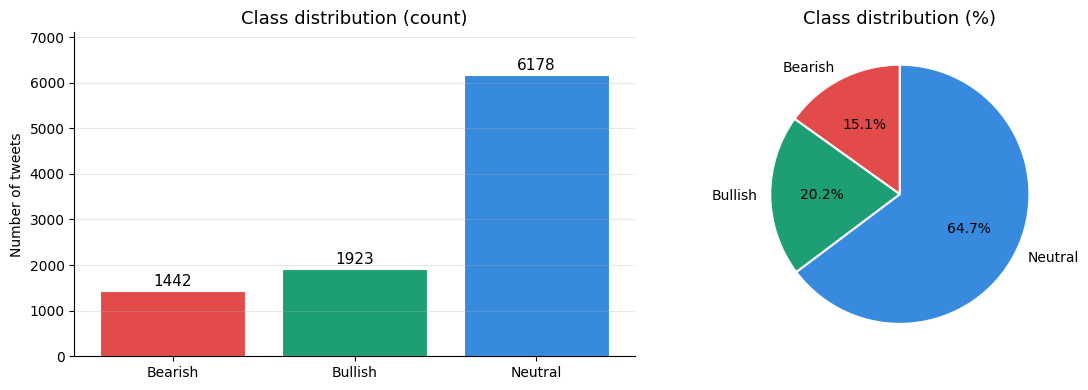


Class counts:
  Bearish  (0):  1442  (15.1%)
  Bullish  (1):  1923  (20.2%)
  Neutral  (2):  6178  (64.7%)


In [10]:
counts = train['label'].value_counts().sort_index()
pct    = counts / len(train) * 100

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Absolute counts
bars = axes[0].bar(
    [LABEL_MAP[i] for i in counts.index],
    counts.values,
    color=[COLORS[i] for i in counts.index],
    edgecolor='white', linewidth=0.8
)
for bar, v in zip(bars, counts.values):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 30,
                 str(v), ha='center', va='bottom', fontsize=11)
axes[0].set_title('Class distribution (count)', fontsize=13)
axes[0].set_ylabel('Number of tweets')
axes[0].set_ylim(0, counts.max() * 1.15)
axes[0].grid(axis='y', alpha=0.3)
axes[0].spines[['top','right']].set_visible(False)

# Percentage pie
axes[1].pie(
    pct.values,
    labels=[LABEL_MAP[i] for i in pct.index],
    colors=[COLORS[i] for i in pct.index],
    autopct='%1.1f%%',
    startangle=90,
    wedgeprops=dict(edgecolor='white', linewidth=1.5)
)
axes[1].set_title('Class distribution (%)', fontsize=13)

plt.tight_layout()
plt.savefig('fig_class_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

print('\nClass counts:')
for i, (c, p) in enumerate(zip(counts, pct)):
    print(f'  {LABEL_MAP[i]:8s} ({i}): {c:5d}  ({p:.1f}%)')

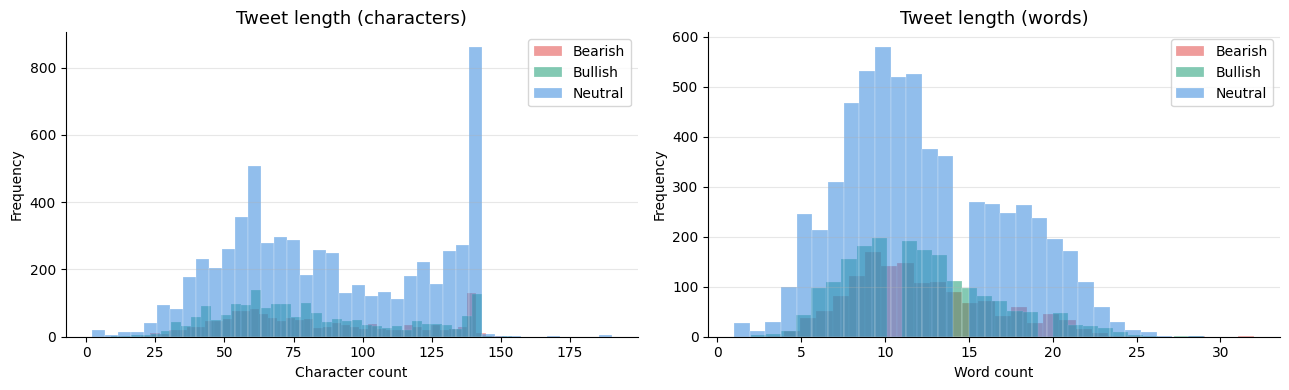


Mean word count per class:
label
Bearish    12.000693
Bullish    11.926157
Neutral    12.298317
Name: word_len, dtype: float64


In [11]:
train['char_len']  = train['text'].str.len()
train['word_len']  = train['text'].str.split().str.len()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for label_id, label_name in LABEL_MAP.items():
    subset = train[train['label'] == label_id]
    axes[0].hist(subset['char_len'],  bins=40, alpha=0.55,
                 color=COLORS[label_id], label=label_name, edgecolor='white', linewidth=0.3)
    axes[1].hist(subset['word_len'],  bins=30, alpha=0.55,
                 color=COLORS[label_id], label=label_name, edgecolor='white', linewidth=0.3)

for ax, xlabel, title in zip(axes,
                              ['Character count', 'Word count'],
                              ['Tweet length (characters)', 'Tweet length (words)']):
    ax.set_xlabel(xlabel)
    ax.set_ylabel('Frequency')
    ax.set_title(title, fontsize=13)
    ax.legend()
    ax.grid(axis='y', alpha=0.3)
    ax.spines[['top','right']].set_visible(False)

plt.tight_layout()
plt.savefig('fig_tweet_length.png', dpi=150, bbox_inches='tight')
plt.show()

print('\nMean word count per class:')
print(train.groupby('label')['word_len'].mean().rename(LABEL_MAP))

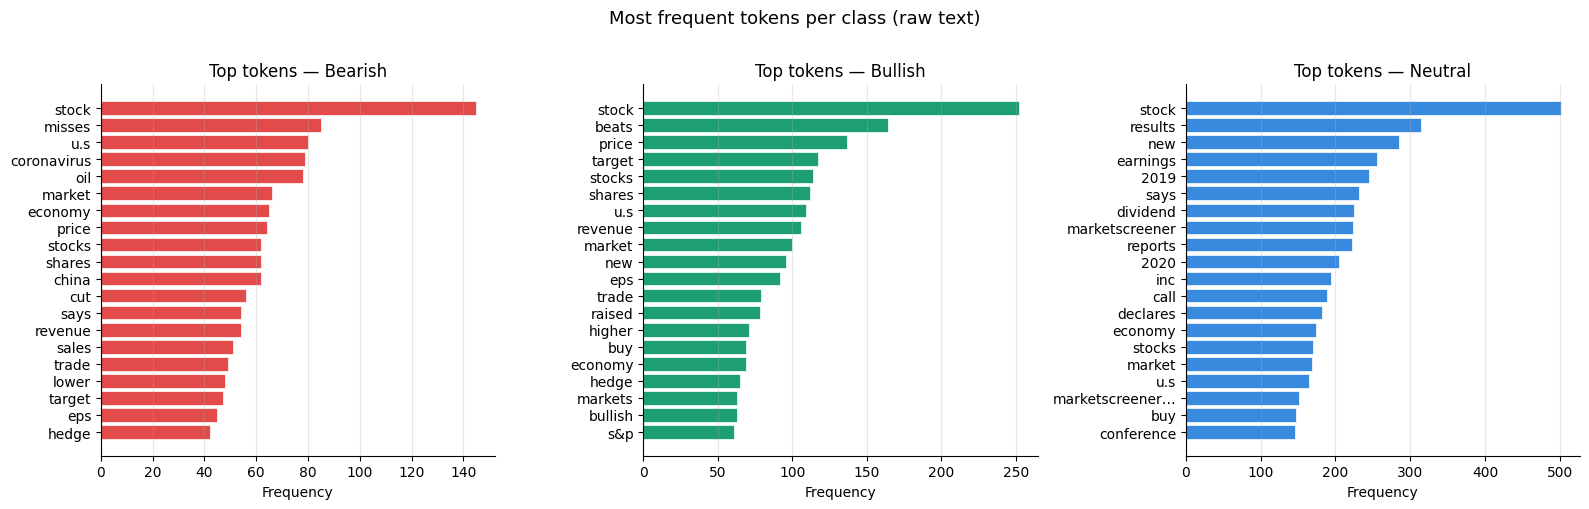

In [12]:
basic_stop = set(stopwords.words('english')) | {'rt', 'amp', 'https', 'co', 'the', 'to', 'a', 'of', 'in', 'is', 'it'}

def top_tokens(texts, n=20):
    tokens = ' '.join(texts).lower().split()
    tokens = [t.strip(string.punctuation) for t in tokens if t.strip(string.punctuation) not in basic_stop and len(t) > 2]
    return Counter(tokens).most_common(n)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, (label_id, label_name) in zip(axes, LABEL_MAP.items()):
    subset = train[train['label'] == label_id]['text']
    top = top_tokens(subset)
    words, freqs = zip(*top)
    ax.barh(list(reversed(words)), list(reversed(freqs)),
            color=COLORS[label_id], edgecolor='white', linewidth=0.5)
    ax.set_title(f'Top tokens — {label_name}', fontsize=12)
    ax.set_xlabel('Frequency')
    ax.grid(axis='x', alpha=0.3)
    ax.spines[['top','right']].set_visible(False)

plt.suptitle('Most frequent tokens per class (raw text)', fontsize=13, y=1.01)
plt.tight_layout()
plt.savefig('fig_top_tokens.png', dpi=150, bbox_inches='tight')
plt.show()

In [13]:
import string

basic_stop = set(stopwords.words('english')) | {'rt', 'amp', 'https', 'co', 'http'}

def top_tokens(texts, n=15):
    tokens = ' '.join(texts).lower().split()
    tokens = [t.strip(string.punctuation) for t in tokens
              if t.strip(string.punctuation) not in basic_stop and len(t) > 2]
    return Counter(tokens).most_common(n)

for label_id, label_name in LABEL_MAP.items():
    subset = train[train['label'] == label_id]['text']
    top = top_tokens(subset)
    print(f"\n{label_name} ({label_id}):")
    for word, freq in top:
        print(f"  {word:<20} {freq}")


Bearish (0):
  stock                145
  misses               85
  u.s                  80
  coronavirus          79
  oil                  78
  market               66
  economy              65
  price                64
  stocks               62
  shares               62
  china                62
  cut                  56
  says                 54
  revenue              54
  sales                51

Bullish (1):
  stock                252
  beats                164
  price                137
  target               117
  stocks               114
  shares               112
  u.s                  109
  revenue              106
  market               100
  new                  96
  eps                  92
  trade                79
  raised               78
  higher               71
  buy                  69

Neutral (2):
  stock                502
  results              315
  new                  285
  earnings             256
  2019                 245
  says                 231
  divi

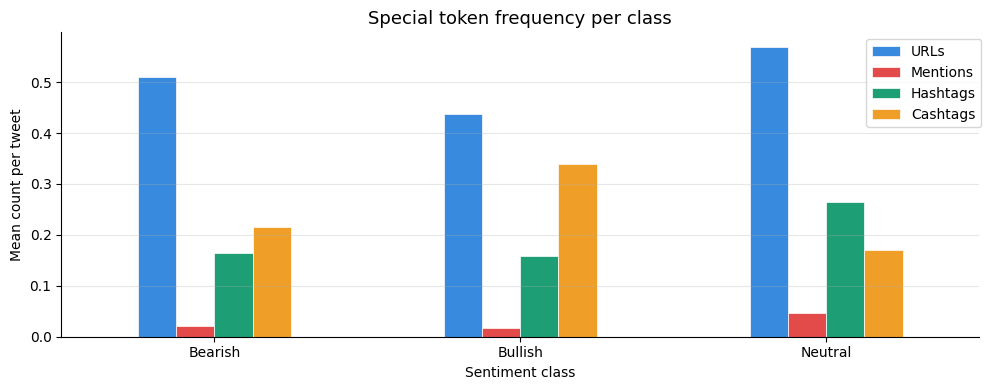

         n_urls  n_mentions  n_hashtags  n_cashtags
label                                              
Bearish   0.510       0.021       0.165       0.216
Bullish   0.438       0.017       0.158       0.340
Neutral   0.569       0.046       0.265       0.171


In [14]:
def count_pattern(series, pattern):
    return series.str.findall(pattern).str.len()

train['n_urls']      = count_pattern(train['text'], r'https?://\S+')
train['n_mentions']  = count_pattern(train['text'], r'@\w+')
train['n_hashtags']  = count_pattern(train['text'], r'#\w+')
train['n_cashtags']  = count_pattern(train['text'], r'\$[A-Z]{1,5}')

features = ['n_urls', 'n_mentions', 'n_hashtags', 'n_cashtags']
means = train.groupby('label')[features].mean().rename(index=LABEL_MAP)

ax = means.plot(kind='bar', figsize=(10, 4), color=['#378ADD','#E24B4A','#1D9E75','#EF9F27'],
                edgecolor='white', linewidth=0.5)
ax.set_xlabel('Sentiment class')
ax.set_ylabel('Mean count per tweet')
ax.set_title('Special token frequency per class', fontsize=13)
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
ax.legend(['URLs', 'Mentions', 'Hashtags', 'Cashtags'], bbox_to_anchor=(1.01, 1))
ax.grid(axis='y', alpha=0.3)
ax.spines[['top','right']].set_visible(False)
plt.tight_layout()
plt.savefig('fig_special_tokens.png', dpi=150, bbox_inches='tight')
plt.show()

print(means.round(3))

In [15]:
train['has_ticker']  = train['text'].apply(lambda x: bool(re.search(r'\$[A-Z]{1,5}', x)))
train['has_hashtag'] = train['text'].apply(lambda x: bool(re.search(r'#\w+', x)))
train['has_url']     = train['text'].apply(lambda x: bool(re.search(r'http', x)))

feature_cols   = ['has_ticker', 'has_hashtag', 'has_url']
feature_labels = ['Stock Ticker ($)', 'Hashtag (#)', 'URL (http)']

print('Presence by class (%):')
print(f"{'':22s} {'Overall':>10} {'Bearish':>10} {'Bullish':>10} {'Neutral':>10}")
for col, lbl in zip(feature_cols, feature_labels):
    overall = train[col].mean() * 100
    vals    = train.groupby('label')[col].mean() * 100
    print(f"  {lbl:20s}: {overall:>9.1f}% {vals[0]:>9.1f}% {vals[1]:>9.1f}% {vals[2]:>9.1f}%")

Presence by class (%):
                          Overall    Bearish    Bullish    Neutral
  Stock Ticker ($)    :      15.0%      13.9%      25.0%      12.1%
  Hashtag (#)         :       9.4%       6.8%       6.2%      11.0%
  URL (http)          :      46.8%      44.3%      39.1%      49.8%


In [17]:
! pip install langdetect

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 981.5/981.5 kB 15.4 MB/s eta 0:00:00a 0:00:01
  Preparing metadata (setup.py) ... done
  Created wheel for langdetect: filename=langdetect-1.0.9-py3-none-any.whl size=993223 sha256=e484bff31e5d9e5b209de09435136cfdb7abde7c4636dc999ac5fed321df4c06
  Stored in directory: /root/.cache/pip/wheels/c1/67/88/e844b5b022812e15a52e4eaa38a1e709e99f06f6639d7e3ba7
Successfully built langdetect


In [18]:
from langdetect import detect

def safe_detect(text):
    try:
        return detect(text)
    except:
        return 'unknown'

train['lang'] = train['text'].apply(safe_detect)

print('Language distribution:')
print(train['lang'].value_counts().head(10))
print()
print('Non-English tweets:', (train['lang'] != 'en').sum(),
      f"({(train['lang'] != 'en').mean()*100:.1f}%)")
print()
print('Non-English by class (%):')
non_en = train[train['lang'] != 'en'].groupby('label').size()
total  = train.groupby('label').size()
print((non_en / total * 100).rename(LABEL_MAP).round(2))

Language distribution:
lang
en    8857
de     107
ca     107
es      86
fr      83
sv      64
da      40
no      33
nl      32
it      27
Name: count, dtype: int64

Non-English tweets: 686 (7.2%)

Non-English by class (%):
label
Bearish    6.38
Bullish    6.14
Neutral    7.70
dtype: float64


In [19]:
print('Sample non-English tweets:')
print(train[train['lang'] != 'en'][['text', 'lang']].sample(30, random_state=42).to_string())

Sample non-English tweets:
                                                                                                                                         text lang
3019                                                      Oil drops after U.S. inventory data https://t.co/IDCJ372Mjb https://t.co/hSyzKTVifN   da
9277                                                                                                    Aquestive shares jump on FDA approval   fr
2814                                                                                                               KonaTel reports Q3 results   ca
3894                                                                                        "Let’s do push-ups, man." https://t.co/U8QVQkICIh   fr
3450                                                                       General Motors' Q4 Profit Beat Estimates Despite Huge Strike Costs   de
2510                                                                         $DNZOF $DNZOY 

In [20]:
train = train.drop(columns=['lang'])

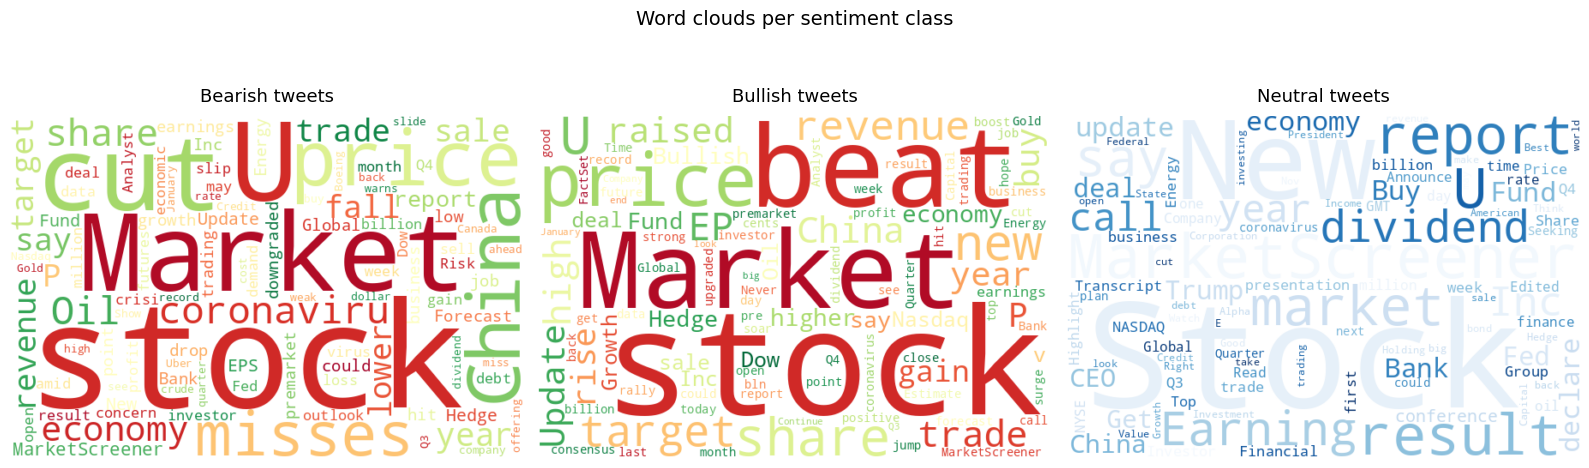

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, (label_id, label_name) in zip(axes, LABEL_MAP.items()):
    text_blob = ' '.join(train[train['label'] == label_id]['text'])
    wc = WordCloud(
        width=600, height=400,
        background_color='white',
        colormap='RdYlGn' if label_id != 2 else 'Blues',
        stopwords=basic_stop,
        max_words=100,
        collocations=False,
        random_state=RANDOM_STATE
    ).generate(text_blob)
    ax.imshow(wc, interpolation='bilinear')
    ax.set_title(f'{label_name} tweets', fontsize=13, pad=10)
    ax.axis('off')

plt.suptitle('Word clouds per sentiment class', fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig('fig_wordclouds.png', dpi=150, bbox_inches='tight')
plt.show()

In [22]:
import emoji

def has_emoji(text):
    return any(char in emoji.EMOJI_DATA for char in text)

emoji_counts = train.groupby('label')['text'].apply(lambda x: x.apply(has_emoji).sum())
emoji_pct    = emoji_counts / train.groupby('label')['text'].count() * 100

print('Tweets containing emojis (%):')
print(emoji_pct.rename(LABEL_MAP).round(2))

Tweets containing emojis (%):
label
Bearish    0.00
Bullish    0.16
Neutral    0.76
Name: text, dtype: float64


# Dataset Overview

The training set contains **9,543 tweets** with no missing values and no duplicate entries. Each tweet is labelled as **Bearish (0)**, **Bullish (1)**, or **Neutral (2)**.

## Class Imbalance

The dataset is heavily imbalanced: **Neutral** dominates at **64.7%** (6,178 tweets), followed by **Bullish** at **20.2%** (1,923) and **Bearish** at **15.1%** (1,442). This imbalance means that accuracy is a misleading metric; therefore, **macro-averaged F1-score** is used as the primary evaluation criterion throughout the project. The train/validation split was performed using stratification to preserve these class proportions.

## Tweet Length

Mean tweet length is nearly identical across all three classes (approximately **12 words per tweet**). Tweet length is therefore not expected to be a discriminative feature.

## Vocabulary Analysis

Vocabulary is strongly class-discriminative. Bullish and Bearish tweets share earnings-related language but in opposite directions. Terms such as **"beats"** (164 occurrences, Bullish only) are among the strongest Bullish indicators, while **"misses"** (85 occurrences, Bearish only) is highly associated with Bearish sentiment.

Analyst action words further distinguish the classes:

- **Bullish:** *raised*, *higher*, *buy*
- **Bearish:** *cut*, *coronavirus*

Neutral tweets are dominated by announcement-style vocabulary such as *declares*, *reports*, *dividend*, and *earnings*, suggesting that Neutral represents a distinct newswire-style register rather than simply the absence of sentiment.

Common financial terms such as *stock* and *market* appear consistently across all classes and therefore provide little discriminative value.

## Special Token Analysis

Bullish tweets contain stock tickers (cashtags) at nearly twice the rate of the other classes:

| Class | Cashtag Rate |
|---------|------------:|
| Bullish | 25.0% |
| Bearish | 13.9% |
| Neutral | 12.1% |

This suggests that positive sentiment is more frequently directed at specific assets.

URLs appear uniformly across classes (39–50%) and carry little sentiment information. User mentions (`@user`) are negligible across all classes (mean ≤ 0.05 per tweet).

These findings directly informed preprocessing decisions:

- Preserve cashtags
- Remove URLs
- Remove user mentions

## Language Analysis

Using `langdetect`, **7.2%** of tweets were flagged as non-English. Manual inspection of a random sample of 30 tweets showed that these were predominantly false positives. English financial shorthand, ticker symbols, acronyms, and numeric-heavy text were frequently misclassified due to sparse natural language content.

Only **2 genuinely non-English tweets** (Italian) were identified in the sample. Given the negligible true non-English rate, no tweets were removed based on language.

Emoji presence is negligible across all classes (≤0.76%), confirming that their removal during preprocessing introduces no meaningful information loss.

# Split & Pre Processing

In [23]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9543 entries, 0 to 9542
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   text         9543 non-null   object
 1   label        9543 non-null   int64 
 2   char_len     9543 non-null   int64 
 3   word_len     9543 non-null   int64 
 4   n_urls       9543 non-null   int64 
 5   n_mentions   9543 non-null   int64 
 6   n_hashtags   9543 non-null   int64 
 7   n_cashtags   9543 non-null   int64 
 8   has_ticker   9543 non-null   bool  
 9   has_hashtag  9543 non-null   bool  
 10  has_url      9543 non-null   bool  
dtypes: bool(3), int64(7), object(1)
memory usage: 624.5+ KB


In [24]:
train_clean = train[['text', 'label']].copy()

In [25]:
train_df, val_df = train_test_split(
    train_clean,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=train_clean['label']
)

In [26]:
print(f'Train size : {len(train_df):,}  ({len(train_df)/len(train_clean)*100:.0f}%)')
print(f'Val   size : {len(val_df):,}  ({len(val_df)/len(train_clean)*100:.0f}%)')
print()
print('Class proportions after split:')
orig = train_clean['label'].value_counts(normalize=True).sort_index().rename('Original')
trn  = train_df['label'].value_counts(normalize=True).sort_index().rename('Train')
val  = val_df['label'].value_counts(normalize=True).sort_index().rename('Val')
print(pd.concat([orig, trn, val], axis=1).rename(index=LABEL_MAP).applymap(lambda x: f'{x:.3f}'))

Train size : 7,634  (80%)
Val   size : 1,909  (20%)

Class proportions after split:
        Original  Train    Val
label                         
Bearish    0.151  0.151  0.151
Bullish    0.202  0.201  0.202
Neutral    0.647  0.647  0.647


/tmp/ipykernel_58/1035290561.py:8: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  print(pd.concat([orig, trn, val], axis=1).rename(index=LABEL_MAP).applymap(lambda x: f'{x:.3f}'))


In [27]:
# Imports
import re
import string
import nltk
from nltk.corpus import stopwords, wordnet
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import TweetTokenizer
from nltk import pos_tag

nltk.download('stopwords',                  quiet=True)
nltk.download('wordnet',                    quiet=True)
nltk.download('omw-1.4',                    quiet=True)
nltk.download('averaged_perceptron_tagger', quiet=True)
nltk.download('averaged_perceptron_tagger_eng', quiet=True)

lemmatizer = WordNetLemmatizer()
tweet_tok  = TweetTokenizer(strip_handles=False, reduce_len=True)
stop_words = set(stopwords.words('english')) | {
    'marketscreener',
    'rt', 'amp', 'via'
}

def get_wordnet_pos(tag):
    if tag.startswith('J'): return wordnet.ADJ
    if tag.startswith('V'): return wordnet.VERB
    if tag.startswith('R'): return wordnet.ADV
    return wordnet.NOUN

def preprocess(text: str) -> str:
    """
    Preprocessing pipeline — 4 techniques:
      1. Regex cleaning     — remove URLs, @mentions, RT prefix, HTML entities,
                              hashtags, non-ASCII/emojis
      2. Tokenization       — TweetTokenizer
      3. Stop-word removal  — NLTK English + custom artifacts from exploration
                              Cashtags ($AAPL) explicitly preserved
      4. Lemmatization      — POS-aware WordNetLemmatizer
    """
    #Regex cleaning
    text = re.sub(r'http\S+|www\.\S+', '', text)          # remove URLs
    text = re.sub(r'@\w+', '', text)                       # remove @mentions
    text = re.sub(r'^RT[\s]+', '', text)                   # remove RT prefix
    text = re.sub(r'&amp;', '&', text)                     # decode HTML entity
    text = re.sub(r'\$([A-Z]{1,5})', r'TICKER_\1', text)  # protect cashtags
    text = re.sub(r'#\w+', '', text)                       # remove hashtags
    text = re.sub(r'[^\x00-\x7F]+', '', text)             # remove non-ASCII / emojis
    text = re.sub(r'\s+', ' ', text).strip()               # collapse whitespace

    #Tokenization
    tokens = tweet_tok.tokenize(text.lower())

    #Stop-word removal
    cleaned = []
    for t in tokens:
        if t.startswith('ticker_'):
            cleaned.append(t)
        elif (t not in stop_words
              and t not in string.punctuation
              and not re.match(r'^[^a-z]+$', t)
              and len(t) > 1):
            cleaned.append(t)

    #POS-aware lemmatization — skip cashtags
    tagged = pos_tag(cleaned)
    tokens = [
        t if t.startswith('ticker_')
        else lemmatizer.lemmatize(t, get_wordnet_pos(pos))
        for t, pos in tagged
    ]

    #restore cashtag $ prefix
    result = ' '.join(tokens)
    result = re.sub(r'ticker_([a-z]{1,5})', r'$\1', result)
    return result


def preprocess_transformer(text: str) -> str:
    """
    Light cleaning for transformer-based models (FinBERT, RoBERTa).
    Removes noise but preserves natural language structure —
    no stop word removal, no lemmatization, no tokenization changes.
    """
    text = re.sub(r'http\S+|www\.\S+', '', text)    # remove URLs
    text = re.sub(r'@\w+', '', text)                 # remove @mentions
    text = re.sub(r'^RT[\s]+', '', text)             # remove RT prefix
    text = re.sub(r'&amp;', '&', text)               # decode HTML entity
    text = re.sub(r'#\w+', '', text)                 # remove hashtags
    text = re.sub(r'[^\x00-\x7F]+', '', text)       # remove non-ASCII / emojis
    text = re.sub(r'\s+', ' ', text).strip()         # collapse whitespace
    return text


In [28]:
# Apply preprocessing
train_df['text_clean']       = train_df['text'].apply(preprocess)
val_df['text_clean']         = val_df['text'].apply(preprocess)
test['text_clean']           = test['text'].apply(preprocess)

train_df['text_transformer'] = train_df['text'].apply(preprocess_transformer)
val_df['text_transformer']   = val_df['text'].apply(preprocess_transformer)
test['text_transformer']     = test['text'].apply(preprocess_transformer)

print('Done.')
print(f'Empty after preprocessing — train : {(train_df["text_clean"].str.strip() == "").sum()}')
print(f'Empty after preprocessing — val   : {(val_df["text_clean"].str.strip() == "").sum()}')
print(f'Empty after preprocessing — test  : {(test["text_clean"].str.strip() == "").sum()}')

Done.
Empty after preprocessing — train : 7
Empty after preprocessing — val   : 1
Empty after preprocessing — test  : 1


In [29]:
# Handle empty tweets
train_df = train_df[train_df['text_clean'].str.strip() != ''].reset_index(drop=True)
val_df   = val_df[val_df['text_clean'].str.strip() != ''].reset_index(drop=True)

# placeholder for empty test tweets
test.loc[test['text_clean'].str.strip() == '', 'text_clean']           = 'unk'
test.loc[test['text_transformer'].str.strip() == '', 'text_transformer'] = 'unk'

In [30]:
test_cases = [
    "RT @user: $AAPL beats EPS by $0.06 https://t.co/abc123",
    "$BTC to the moon!! 🚀🚀",
    "Stocks fell as coronavirus fears grow in China https://t.co/xyz",
    "Verseon : Update on Tender Offer #Verseon #Stock #MarketScreener https://t.co/abc",
    "Ubiquiti EPS misses by $0.06, misses on revenue"
]
for t in test_cases:
    print(f"IN  : {t}")
    print(f"OUT : {preprocess(t)}")
    print()

IN  : RT @user: $AAPL beats EPS by $0.06 https://t.co/abc123
OUT : $aapl beat eps

IN  : $BTC to the moon!! 🚀🚀
OUT : $btc moon

IN  : Stocks fell as coronavirus fears grow in China https://t.co/xyz
OUT : stock fell coronavirus fear grow china

IN  : Verseon : Update on Tender Offer #Verseon #Stock #MarketScreener https://t.co/abc
OUT : verseon update tender offer

IN  : Ubiquiti EPS misses by $0.06, misses on revenue
OUT : ubiquiti eps miss miss revenue



In [31]:
test_cases = [
    "RT @user: $AAPL beats EPS by $0.06 https://t.co/abc123",
    "$BTC to the moon!! 🚀🚀",
    "Stocks fell as coronavirus fears grow in China https://t.co/xyz",
]
for t in test_cases:
    print(f"IN          : {t}")
    print(f"text_clean  : {preprocess(t)}")
    print(f"text_transf : {preprocess_transformer(t)}")
    print()

IN          : RT @user: $AAPL beats EPS by $0.06 https://t.co/abc123
text_clean  : $aapl beat eps
text_transf : : $AAPL beats EPS by $0.06

IN          : $BTC to the moon!! 🚀🚀
text_clean  : $btc moon
text_transf : $BTC to the moon!!

IN          : Stocks fell as coronavirus fears grow in China https://t.co/xyz
text_clean  : stock fell coronavirus fear grow china
text_transf : Stocks fell as coronavirus fears grow in China



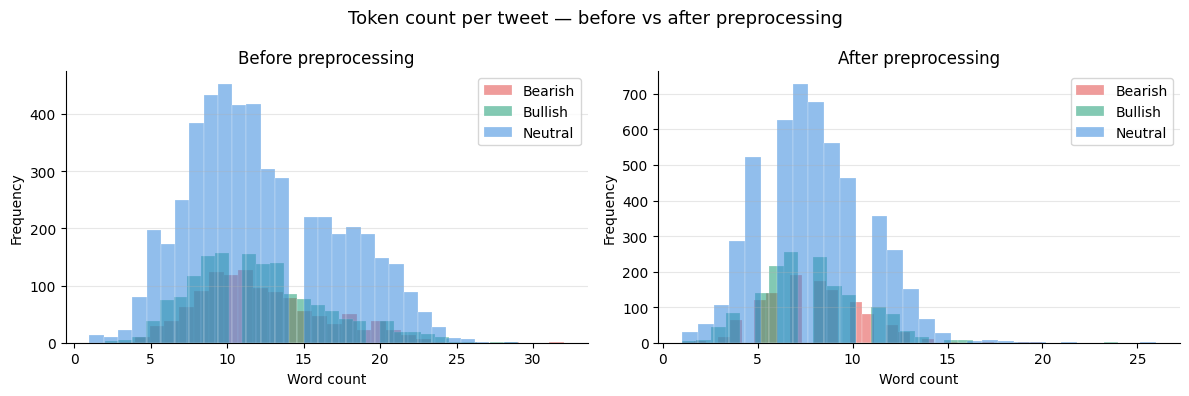

Mean token count before: 12.2
Mean token count after : 7.9


In [32]:
# recompute word_len on train_df
train_df['word_len']       = train_df['text'].str.split().str.len()
train_df['word_len_clean'] = train_df['text_clean'].str.split().str.len()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col, title in zip(axes,
                           ['word_len', 'word_len_clean'],
                           ['Before preprocessing', 'After preprocessing']):
    for label_id, label_name in LABEL_MAP.items():
        subset = train_df[train_df['label'] == label_id]
        ax.hist(subset[col], bins=30, alpha=0.55,
                color=COLORS[label_id], label=label_name, edgecolor='white', linewidth=0.3)
    ax.set_title(title, fontsize=12)
    ax.set_xlabel('Word count')
    ax.set_ylabel('Frequency')
    ax.legend()
    ax.grid(axis='y', alpha=0.3)
    ax.spines[['top','right']].set_visible(False)

plt.suptitle('Token count per tweet — before vs after preprocessing', fontsize=13)
plt.tight_layout()
plt.savefig('fig_preprocessing_effect.png', dpi=150, bbox_inches='tight')
plt.show()

print('Mean token count before:', train_df['word_len'].mean().round(1))
print('Mean token count after :', train_df['word_len_clean'].mean().round(1))

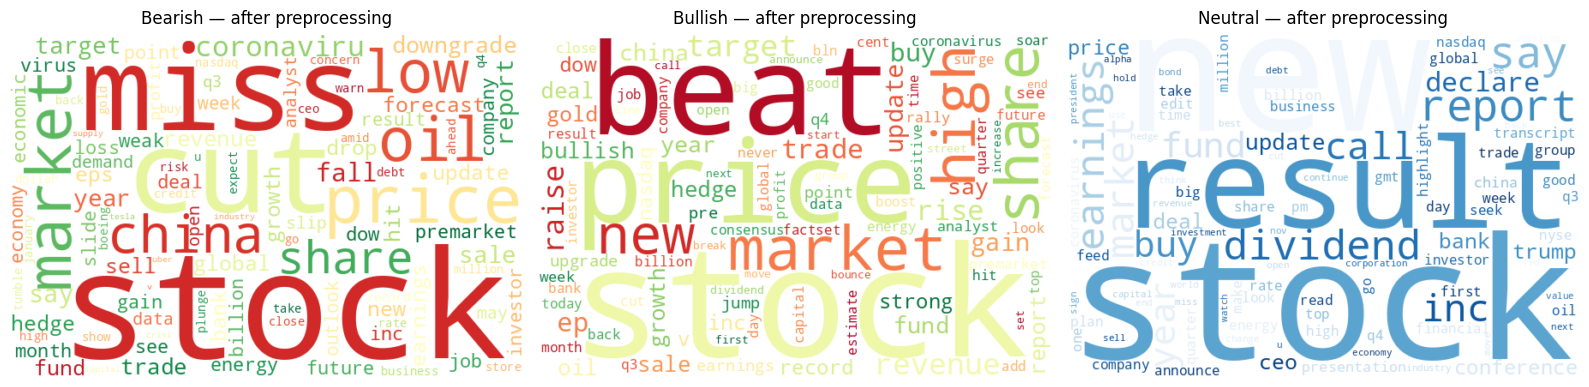

In [33]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, (label_id, label_name) in zip(axes, LABEL_MAP.items()):
    text_blob = ' '.join(train_df[train_df['label'] == label_id]['text_clean'])
    wc = WordCloud(
        width=600, height=400,
        background_color='white',
        colormap='RdYlGn' if label_id != 2 else 'Blues',
        max_words=100,
        collocations=False,
        random_state=RANDOM_STATE
    ).generate(text_blob)
    ax.imshow(wc, interpolation='bilinear')
    ax.set_title(f'{label_name} — after preprocessing', fontsize=12, pad=8)
    ax.axis('off')

plt.tight_layout()
plt.savefig('fig_wordclouds_clean.png', dpi=150, bbox_inches='tight')
plt.show()

## 4. Data Preprocessing

The preprocessing pipeline implements four techniques, each justified by findings from the exploratory analysis.

### Technique 1 — Regex Cleaning

Several regular expression rules are applied to remove noise identified during exploration:

| Pattern | Action | Justification |
|---|---|---|
| URLs (`http`, `www`) | Removed | Appear uniformly across classes (39–50%), no sentiment signal |
| @mentions | Removed | Mean occurrence ≤0.046 across all classes, no discriminative value |
| RT prefix | Removed | Structural Twitter artifact, not authored content |
| Hashtags (`#word`) | Removed | Presence showed no meaningful class difference (6.2–11.0%) |
| Non-ASCII / emojis | Removed | Emoji presence negligible across all classes (≤0.76%) |
| Cashtags (`$AAPL`) | **Preserved** | Bullish tweets have 2× ticker presence (25.0%) vs Neutral (12.1%) — confirmed discriminative signal in exploration |

### Technique 2 — Tokenization

`TweetTokenizer` (NLTK) was chosen over basic `split()` because the dataset consists of Twitter text. It correctly handles contractions, elongated words, and punctuation attached to tokens without destroying them. Basic splitting would produce noisy tokens such as `"revenue."` or `"stock,"` with trailing punctuation.

### Technique 3 — Stop-word Removal

Standard English stop words carry no sentiment signal. Custom tokens were added based on exploration findings:

- `marketscreener` — appeared 224 times in Neutral tweets as a source domain artifact
- `rt`, `amp`, `via` — Twitter and HTML encoding artifacts with no semantic content

### Technique 4 — Lemmatization

Lemmatization reduces inflected forms to their base, which is critical for the most discriminative tokens in the dataset: `beats`→`beat`, `misses`→`miss`, `raised`→`raise`. A **POS-aware** implementation was used (via NLTK `pos_tag`) rather than the default noun-only lemmatization, ensuring verbs are correctly reduced. Lemmatization was preferred over stemming because transformer-based models rely on recognisable vocabulary — stemmed tokens can produce non-standard forms that fall outside a model's learned vocabulary.

> **Note:** Cashtags are explicitly excluded from lemmatization to preserve their original form (`$aapl` remains `$aapl`).

In [34]:
train_df = train_df[['text', 'label', 'text_clean', 'text_transformer']]
val_df   = val_df[['text', 'label', 'text_clean', 'text_transformer']]
test     = test[['id', 'text', 'text_clean', 'text_transformer']]

In [ ]:
# Save
train_df.to_csv('train_processed.csv', index=False)
val_df.to_csv('val_processed.csv',     index=False)
test.to_csv('test_processed.csv',      index=False)

print(f'\nFinal sizes — train: {len(train_df)}, val: {len(val_df)}, test: {len(test)}')
print(f'train_df columns: {list(train_df.columns)}')
print(f'val_df   columns: {list(val_df.columns)}')
print(f'test     columns: {list(test.columns)}')

# Part 2

In [2]:
np.random.seed(42)

In [3]:
import torch
print("GPU available:", torch.cuda.is_available())
print("Device:", torch.cuda.get_device_name(0))

train_df = pd.read_csv('/kaggle/input/datasets/duartecneves/textmining/train_processed.csv')
val_df   = pd.read_csv('/kaggle/input/datasets/duartecneves/textmining/val_processed.csv')
test = pd.read_csv('/kaggle/input/datasets/duartecneves/textmining/test_processed.csv')

GPU available: True
Device: Tesla T4


In [4]:
print(f'Train: {len(train_df)}, Val: {len(val_df)}, Test: {len(test)}')
print(f'Train columns: {train_df.columns.tolist()}')
print(f'Val   columns: {val_df.columns.tolist()}')
print(f'Test  columns: {test.columns.tolist()}')

Train: 7627, Val: 1908, Test: 2388
Train columns: ['text', 'label', 'text_clean', 'text_transformer']
Val   columns: ['text', 'label', 'text_clean', 'text_transformer']
Test  columns: ['id', 'text', 'text_clean', 'text_transformer']


## Feature Engineering

### TF-IDF

In [5]:
from sklearn.feature_extraction.text import TfidfVectorizer
import scipy.sparse as sp

# Variation 1: Unigrams
tfidf_unigram = TfidfVectorizer(
    ngram_range=(1, 1),
    max_features=20000,
    min_df=2,          # ignore terms appearing in less than 2 documents
    sublinear_tf=True  # apply log normalization to term frequencies
)

X_train_unigram = tfidf_unigram.fit_transform(train_df['text_clean'])
X_val_unigram   = tfidf_unigram.transform(val_df['text_clean'])
X_test_unigram  = tfidf_unigram.transform(test['text_clean'])

print(f'Unigram — train: {X_train_unigram.shape}, val: {X_val_unigram.shape}, test: {X_test_unigram.shape}')

# Variation 2: Unigrams + Bigrams
tfidf_bigram = TfidfVectorizer(
    ngram_range=(1, 2),
    max_features=30000,
    min_df=2,
    sublinear_tf=True
)

X_train_bigram = tfidf_bigram.fit_transform(train_df['text_clean'])
X_val_bigram   = tfidf_bigram.transform(val_df['text_clean'])
X_test_bigram  = tfidf_bigram.transform(test['text_clean'])

print(f'Bigram  — train: {X_train_bigram.shape}, val: {X_val_bigram.shape}, test: {X_test_bigram.shape}')

y_train = train_df['label'].values
y_val   = val_df['label'].values

Unigram — train: (7627, 5097), val: (1908, 5097), test: (2388, 5097)
Bigram  — train: (7627, 9873), val: (1908, 9873), test: (2388, 9873)


### Word2Vec

In [6]:
from gensim.models import Word2Vec
import numpy as np

train_tokens = train_df['text_clean'].apply(str.split).tolist()
val_tokens   = val_df['text_clean'].apply(str.split).tolist()
test_tokens  = test['text_clean'].apply(str.split).tolist()

# Variation 1: Train Word2Vec on the corpus
w2v_model = Word2Vec(
    sentences=train_tokens,
    vector_size=100,    # embedding dimension
    window=5,           # context window
    min_count=2,        # ignore words appearing less than 2 times
    workers=4,
    seed=42,
    epochs=10
)

print(f'Vocabulary size: {len(w2v_model.wv)}')

# average word vectors per tweet
def get_w2v_embedding(tokens, model, vector_size=100):
    vectors = [model.wv[t] for t in tokens if t in model.wv]
    if len(vectors) == 0:
        return np.zeros(vector_size)
    return np.mean(vectors, axis=0)

X_train_w2v = np.array([get_w2v_embedding(t, w2v_model) for t in train_tokens])
X_val_w2v   = np.array([get_w2v_embedding(t, w2v_model) for t in val_tokens])
X_test_w2v  = np.array([get_w2v_embedding(t, w2v_model) for t in test_tokens])

print(f'Word2Vec own — train: {X_train_w2v.shape}, val: {X_val_w2v.shape}, test: {X_test_w2v.shape}')

Vocabulary size: 5214
Word2Vec own — train: (7627, 100), val: (1908, 100), test: (2388, 100)


In [7]:
import gensim.downloader as api

print('Downloading GloVe Twitter 100...')
w2v_pretrained = api.load('glove-twitter-100')
print('Loaded.')

def get_w2v_embedding_pretrained(tokens, model, vector_size=100):
    vectors = [model[t] for t in tokens if t in model]
    if len(vectors) == 0:
        return np.zeros(vector_size)
    return np.mean(vectors, axis=0)

X_train_w2v_pt = np.array([get_w2v_embedding_pretrained(t, w2v_pretrained) for t in train_tokens])
X_val_w2v_pt   = np.array([get_w2v_embedding_pretrained(t, w2v_pretrained) for t in val_tokens])
X_test_w2v_pt  = np.array([get_w2v_embedding_pretrained(t, w2v_pretrained) for t in test_tokens])

print(f'GloVe Twitter — train: {X_train_w2v_pt.shape}, val: {X_val_w2v_pt.shape}, test: {X_test_w2v_pt.shape}')

[==================================================] 100.0% 387.1/387.1MB downloaded
Loaded.
GloVe Twitter — train: (7627, 100), val: (1908, 100), test: (2388, 100)


### FinBERT

In [21]:
from transformers import AutoTokenizer, AutoModel
import torch
import numpy as np

model_name = 'ProsusAI/finbert'
tokenizer  = AutoTokenizer.from_pretrained(model_name)
model      = AutoModel.from_pretrained(model_name)
model.eval()

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model  = model.to(device)
print(f'Using device: {device}')

def get_cls_embeddings(texts, tokenizer, model, batch_size=64):
    all_embeddings = []
    for i in range(0, len(texts), batch_size):
        batch = texts[i:i+batch_size]
        encoded = tokenizer(
            batch,
            padding=True,
            truncation=True,
            max_length=128,
            return_tensors='pt'
        ).to(device)
        with torch.no_grad():
            output = model(**encoded)
        # extract [CLS] token embedding
        cls_embeddings = output.last_hidden_state[:, 0, :].cpu().numpy()
        all_embeddings.append(cls_embeddings)
        if i % 640 == 0:
            print(f'  processed {i}/{len(texts)}')
    return np.vstack(all_embeddings)

print('Extracting FinBERT embeddings...')
train_texts = train_df['text_transformer'].tolist()
val_texts   = val_df['text_transformer'].tolist()
test_texts  = test['text_transformer'].tolist()

X_train_finbert = get_cls_embeddings(train_texts, tokenizer, model)
print(f'Train done: {X_train_finbert.shape}')

X_val_finbert   = get_cls_embeddings(val_texts, tokenizer, model)
print(f'Val done: {X_val_finbert.shape}')

X_test_finbert  = get_cls_embeddings(test_texts, tokenizer, model)
print(f'Test done: {X_test_finbert.shape}')

config.json:   0%|          | 0.00/758 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/252 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

pytorch_model.bin:   0%|          | 0.00/438M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: ProsusAI/finbert
Key                          | Status     |  | 
-----------------------------+------------+--+-
classifier.bias              | UNEXPECTED |  | 
classifier.weight            | UNEXPECTED |  | 
bert.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


model.safetensors:   0%|          | 0.00/438M [00:00<?, ?B/s]

Using device: cuda
Extracting FinBERT embeddings...
  processed 0/7627
  processed 640/7627
  processed 1280/7627
  processed 1920/7627
  processed 2560/7627
  processed 3200/7627
  processed 3840/7627
  processed 4480/7627
  processed 5120/7627
  processed 5760/7627
  processed 6400/7627
  processed 7040/7627
Train done: (7627, 768)
  processed 0/1908
  processed 640/1908
  processed 1280/1908
Val done: (1908, 768)
  processed 0/2388
  processed 640/2388
  processed 1280/2388
  processed 1920/2388
Test done: (2388, 768)


### RoBERTa

In [22]:
from transformers import AutoTokenizer, AutoModel
import torch

roberta_name      = 'roberta-base'
roberta_tokenizer = AutoTokenizer.from_pretrained(roberta_name)
roberta_model     = AutoModel.from_pretrained(roberta_name)
roberta_model.eval()
roberta_model     = roberta_model.to(device)
print(f'RoBERTa loaded on: {device}')

print('Extracting RoBERTa embeddings...')
X_train_roberta = get_cls_embeddings(train_texts, roberta_tokenizer, roberta_model)
print(f'Train done: {X_train_roberta.shape}')

X_val_roberta   = get_cls_embeddings(val_texts, roberta_tokenizer, roberta_model)
print(f'Val done: {X_val_roberta.shape}')

X_test_roberta  = get_cls_embeddings(test_texts, roberta_tokenizer, roberta_model)
print(f'Test done: {X_test_roberta.shape}')

config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/499M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

RobertaModel LOAD REPORT from: roberta-base
Key                             | Status     | 
--------------------------------+------------+-
lm_head.layer_norm.weight       | UNEXPECTED | 
lm_head.dense.weight            | UNEXPECTED | 
lm_head.layer_norm.bias         | UNEXPECTED | 
roberta.embeddings.position_ids | UNEXPECTED | 
lm_head.dense.bias              | UNEXPECTED | 
lm_head.bias                    | UNEXPECTED | 
pooler.dense.weight             | MISSING    | 
pooler.dense.bias               | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


RoBERTa loaded on: cuda
Extracting RoBERTa embeddings...
  processed 0/7627
  processed 640/7627
  processed 1280/7627
  processed 1920/7627
  processed 2560/7627
  processed 3200/7627
  processed 3840/7627
  processed 4480/7627
  processed 5120/7627
  processed 5760/7627
  processed 6400/7627
  processed 7040/7627
Train done: (7627, 768)
  processed 0/1908
  processed 640/1908
  processed 1280/1908
Val done: (1908, 768)
  processed 0/2388
  processed 640/2388
  processed 1280/2388
  processed 1920/2388
Test done: (2388, 768)


In [9]:
np.save('X_train_finbert.npy', X_train_finbert)
np.save('X_val_finbert.npy',   X_val_finbert)
np.save('X_test_finbert.npy',  X_test_finbert)

np.save('X_train_roberta.npy', X_train_roberta)
np.save('X_val_roberta.npy',   X_val_roberta)
np.save('X_test_roberta.npy',  X_test_roberta)

np.save('X_train_w2v.npy',     X_train_w2v)
np.save('X_val_w2v.npy',       X_val_w2v)
np.save('X_test_w2v.npy',      X_test_w2v)

np.save('X_train_w2v_pt.npy',  X_train_w2v_pt)
np.save('X_val_w2v_pt.npy',    X_val_w2v_pt)
np.save('X_test_w2v_pt.npy',   X_test_w2v_pt)

np.save('y_train.npy', y_train)
np.save('y_val.npy',   y_val)

print('All embeddings saved.')

NameError: name 'X_train_w2v_pt' is not defined

## Models

### Without Class Weights

#### LR with unigram TF-IDF

In [11]:
#Train Logistic Regression on TF-IDF Unigrams 

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Train
lr_unigram = LogisticRegression(
    C=1.0,           # inverse regularization strength
    max_iter=1000,   
    solver='saga',   
    multi_class='multinomial',
    random_state=42,
    n_jobs=-1
)
lr_unigram.fit(X_train_unigram, y_train)

# Evaluate on validation set
y_pred_val = lr_unigram.predict(X_val_unigram)

print("=" * 55)
print("  Logistic Regression — TF-IDF Unigram | Validation")
print("=" * 55)
print(f"\nAccuracy: {accuracy_score(y_val, y_pred_val):.4f}\n")
print(classification_report(y_val, y_pred_val,
                             target_names=['Bearish', 'Bullish', 'Neutral']))

  Logistic Regression — TF-IDF Unigram | Validation

Accuracy: 0.7699

              precision    recall  f1-score   support

     Bearish       0.75      0.36      0.49       288
     Bullish       0.75      0.50      0.60       385
     Neutral       0.77      0.95      0.85      1235

    accuracy                           0.77      1908
   macro avg       0.76      0.60      0.65      1908
weighted avg       0.77      0.77      0.75      1908



/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


In [14]:
#Hyperparameter Sweep (C values) 

from sklearn.metrics import f1_score

C_values = [0.01, 0.1, 1.0, 10.0, 100.0]
val_f1s  = []

for C in C_values:
    clf = LogisticRegression(C=C, max_iter=1000, solver='saga',
                              multi_class='multinomial', random_state=42, n_jobs=-1)
    clf.fit(X_train_unigram, y_train)
    preds = clf.predict(X_val_unigram)
    val_f1s.append(f1_score(y_val, preds, average='macro'))
    print(f'C={C:>7.2f}  macro-F1={val_f1s[-1]:.4f}')

best_C = C_values[np.argmax(val_f1s)]
print(f'\nBest C: {best_C}  (macro-F1={max(val_f1s):.4f})')

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


C=   0.01  macro-F1=0.2620
C=   0.10  macro-F1=0.3982
C=   1.00  macro-F1=0.6465


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


C=  10.00  macro-F1=0.6969


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


C= 100.00  macro-F1=0.6702

Best C: 10.0  (macro-F1=0.6969)


In [15]:
# Re-train with Best C

lr_unigram_best = LogisticRegression(
    C=best_C, max_iter=1000, solver='saga',
    multi_class='multinomial', random_state=42, n_jobs=-1
)
lr_unigram_best.fit(X_train_unigram, y_train)

# Final val metrics with best C
y_pred_best = lr_unigram_best.predict(X_val_unigram)
print(f'Final val accuracy (C={best_C}): {accuracy_score(y_val, y_pred_best):.4f}')
print(classification_report(y_val, y_pred_best,
                             target_names=['Bearish', 'Bullish', 'Neutral']))

Final val accuracy (C=10.0): 0.7851
              precision    recall  f1-score   support

     Bearish       0.66      0.51      0.57       288
     Bullish       0.70      0.61      0.65       385
     Neutral       0.83      0.90      0.86      1235

    accuracy                           0.79      1908
   macro avg       0.73      0.67      0.70      1908
weighted avg       0.78      0.79      0.78      1908



/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


#### LR with bigram TF-IDF

In [18]:
lr_biigram = LogisticRegression(
    C=1.0,           
    max_iter=1000,  
    solver='saga',   
    multi_class='multinomial',
    random_state=42,
    n_jobs=-1
)
lr_biigram.fit(X_train_bigram, y_train)

# Evaluate on validation set
y_pred_val = lr_biigram.predict(X_val_bigram)

print("=" * 55)
print("  Logistic Regression — TF-IDF Bigram | Validation")
print("=" * 55)
print(f"\nAccuracy: {accuracy_score(y_val, y_pred_val):.4f}\n")
print(classification_report(y_val, y_pred_val,
                             target_names=['Bearish', 'Bullish', 'Neutral']))

  Logistic Regression — TF-IDF Bigram | Validation

Accuracy: 0.7762

              precision    recall  f1-score   support

     Bearish       0.81      0.36      0.50       288
     Bullish       0.76      0.51      0.61       385
     Neutral       0.78      0.96      0.86      1235

    accuracy                           0.78      1908
   macro avg       0.78      0.61      0.66      1908
weighted avg       0.78      0.78      0.75      1908



/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


In [19]:
C_values = [0.01, 0.1, 1.0, 10.0, 100.0]
val_f1s  = []

for C in C_values:
    clf = LogisticRegression(C=C, max_iter=1000, solver='saga',
                              multi_class='multinomial', random_state=42, n_jobs=-1)
    clf.fit(X_train_bigram, y_train)
    preds = clf.predict(X_val_bigram)
    val_f1s.append(f1_score(y_val, preds, average='macro'))
    print(f'C={C:>7.2f}  macro-F1={val_f1s[-1]:.4f}')

best_C = C_values[np.argmax(val_f1s)]
print(f'\nBest C: {best_C}  (macro-F1={max(val_f1s):.4f})')

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


C=   0.01  macro-F1=0.2620
C=   0.10  macro-F1=0.3649
C=   1.00  macro-F1=0.6554


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


C=  10.00  macro-F1=0.6949


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


C= 100.00  macro-F1=0.6905

Best C: 10.0  (macro-F1=0.6949)


In [20]:
lr_bigram_best = LogisticRegression(
    C=best_C, max_iter=1000, solver='saga',
    multi_class='multinomial', random_state=42, n_jobs=-1
)
lr_bigram_best.fit(X_train_bigram, y_train)

# Final val metrics with best C
y_pred_best = lr_bigram_best.predict(X_val_bigram)
print(f'Final val accuracy (C={best_C}): {accuracy_score(y_val, y_pred_best):.4f}')
print(classification_report(y_val, y_pred_best,
                             target_names=['Bearish', 'Bullish', 'Neutral']))

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


Final val accuracy (C=10.0): 0.7883
              precision    recall  f1-score   support

     Bearish       0.67      0.49      0.57       288
     Bullish       0.71      0.60      0.65       385
     Neutral       0.83      0.92      0.87      1235

    accuracy                           0.79      1908
   macro avg       0.74      0.67      0.69      1908
weighted avg       0.78      0.79      0.78      1908



#### LR + Word2Vec

In [29]:
scaler_w2v    = StandardScaler()
X_train_w2v_s = scaler_w2v.fit_transform(X_train_w2v)
X_val_w2v_s   = scaler_w2v.transform(X_val_w2v)

scaler_pt      = StandardScaler()
X_train_pt_s   = scaler_pt.fit_transform(X_train_w2v_pt)
X_val_pt_s     = scaler_pt.transform(X_val_w2v_pt)

C_values = [0.01, 0.1, 1.0, 5.0, 10.0, 50.0, 100.0]

def tune_C(X_tr, y_tr, X_val, y_val, class_weight=None):
    best_c, best_f1 = None, -1
    for C in C_values:
        clf = LogisticRegression(
            C=C, max_iter=1000, solver='saga',
            multi_class='multinomial', random_state=42, n_jobs=-1,
            class_weight=class_weight
        )
        clf.fit(X_tr, y_tr)
        f1 = f1_score(y_val, clf.predict(X_val), average='macro')
        print(f'  C={C:>7.2f}  macro-F1={f1:.4f}')
        if f1 > best_f1:
            best_f1, best_c = f1, C
    print(f'  → Best C: {best_c}  (macro-F1={best_f1:.4f})\n')
    return best_c

def evaluate(name, clf, X_val, y_val):
    preds = clf.predict(X_val)
    print("=" * 55)
    print(f"  {name}")
    print("=" * 55)
    print(f"\nAccuracy: {accuracy_score(y_val, preds):.4f}\n")
    print(classification_report(y_val, preds,
                                 target_names=['Bearish', 'Bullish', 'Neutral']))

# ── 1. Word2Vec (own corpus) — No Weights ─────────────────────────────────────
print("── W2V Own | No Weights | C-tuning ──")
best_C_w2v = tune_C(X_train_w2v_s, y_train, X_val_w2v_s, y_val)

lr_w2v = LogisticRegression(
    C=best_C_w2v, max_iter=1000, solver='saga',
    multi_class='multinomial', random_state=42, n_jobs=-1
)
lr_w2v.fit(X_train_w2v_s, y_train)
evaluate('LR + Word2Vec Own | No Weights | Validation', lr_w2v, X_val_w2v_s, y_val)


── W2V Own | No Weights | C-tuning ──


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


  C=   0.01  macro-F1=0.3572


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


  C=   0.10  macro-F1=0.4160


...

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


  C=  50.00  macro-F1=0.4949


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


  C= 100.00  macro-F1=0.4939
  → Best C: 50.0  (macro-F1=0.4949)

  LR + Word2Vec Own | No Weights | Validation

Accuracy: 0.6960

              precision    recall  f1-score   support

     Bearish       0.51      0.15      0.24       288
     Bullish       0.58      0.35      0.44       385
     Neutral       0.72      0.93      0.81      1235

    accuracy                           0.70      1908
   macro avg       0.61      0.48      0.49      1908
weighted avg       0.66      0.70      0.65      1908



/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


In [30]:
print("── GloVe Twitter | No Weights | C-tuning ──")
best_C_pt = tune_C(X_train_pt_s, y_train, X_val_pt_s, y_val)

lr_pt = LogisticRegression(
    C=best_C_pt, max_iter=1000, solver='saga',
    multi_class='multinomial', random_state=42, n_jobs=-1
)
lr_pt.fit(X_train_pt_s, y_train)
evaluate('LR + GloVe Twitter | No Weights | Validation', lr_pt, X_val_pt_s, y_val)

── GloVe Twitter | No Weights | C-tuning ──


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


  C=   0.01  macro-F1=0.5520


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


  C=   0.10  macro-F1=0.5582


...

  C=  50.00  macro-F1=0.5591


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


  C= 100.00  macro-F1=0.5591
  → Best C: 1.0  (macro-F1=0.5591)



/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


  LR + GloVe Twitter | No Weights | Validation

Accuracy: 0.7212

              precision    recall  f1-score   support

     Bearish       0.59      0.29      0.39       288
     Bullish       0.60      0.37      0.45       385
     Neutral       0.75      0.93      0.83      1235

    accuracy                           0.72      1908
   macro avg       0.65      0.53      0.56      1908
weighted avg       0.70      0.72      0.69      1908



#### LR + FinBERT

In [20]:
from sklearn.preprocessing import StandardScaler

X_train_fb = np.load('X_train_finbert.npy')
X_val_fb   = np.load('X_val_finbert.npy')
X_test_fb  = np.load('X_test_finbert.npy')
y_train    = np.load('y_train.npy')
y_val      = np.load('y_val.npy')

print(f'FinBERT embeddings — train: {X_train_fb.shape}, val: {X_val_fb.shape}')

# ── Scale: LR converges better on normalised dense embeddings ─────────────────
scaler      = StandardScaler()
X_train_fb_s = scaler.fit_transform(X_train_fb)
X_val_fb_s   = scaler.transform(X_val_fb)X_test_fb_s  = scaler.transform(X_test_fb)

FinBERT embeddings — train: (7627, 768), val: (1908, 768)


In [22]:

C_values = [0.01, 0.1, 1.0, 10.0, 100.0]
val_f1s  = []

for C in C_values:
    clf = LogisticRegression(C=C, max_iter=1000, solver='saga',
                             multi_class='multinomial', random_state=42, n_jobs=-1)
    clf.fit(X_train_fb_s, y_train)
    preds = clf.predict(X_val_fb_s)
    mf1 = f1_score(y_val, preds, average='macro')
    val_f1s.append(mf1)
    print(f'C={C:>7.2f}  macro-F1={mf1:.4f}')

best_C = C_values[np.argmax(val_f1s)]
print(f'\nBest C: {best_C}  (macro-F1={max(val_f1s):.4f})')

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


C=   0.01  macro-F1=0.7657


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


C=   0.10  macro-F1=0.7550


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


C=   1.00  macro-F1=0.7422


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


C=  10.00  macro-F1=0.7348


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


C= 100.00  macro-F1=0.7348

Best C: 0.01  (macro-F1=0.7657)


In [23]:
lr_finbert = LogisticRegression(
    C=best_C, max_iter=1000, solver='saga',
    multi_class='multinomial', random_state=42, n_jobs=-1

    
)
lr_finbert.fit(X_train_fb_s, y_train)

y_pred_val = lr_finbert.predict(X_val_fb_s)

print("=" * 55)
print("  Logistic Regression — FinBERT CLS | Validation")
print("=" * 55)
print(f"\nAccuracy: {accuracy_score(y_val, y_pred_val):.4f}\n")
print(classification_report(y_val, y_pred_val,
                             target_names=['Bearish', 'Bullish', 'Neutral']))

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


  Logistic Regression — FinBERT CLS | Validation

Accuracy: 0.8281

              precision    recall  f1-score   support

     Bearish       0.72      0.64      0.68       288
     Bullish       0.78      0.69      0.73       385
     Neutral       0.86      0.92      0.89      1235

    accuracy                           0.83      1908
   macro avg       0.79      0.75      0.77      1908
weighted avg       0.82      0.83      0.82      1908



#### LR with RoBERTa

In [26]:
X_train_rb = np.load('X_train_roberta.npy')
X_val_rb   = np.load('X_val_roberta.npy')
X_test_rb  = np.load('X_test_roberta.npy')
y_train    = np.load('y_train.npy')
y_val      = np.load('y_val.npy')

print(f'RoBERTa embeddings — train: {X_train_rb.shape}, val: {X_val_rb.shape}')

scaler       = StandardScaler()
X_train_rb_s = scaler.fit_transform(X_train_rb)
X_val_rb_s   = scaler.transform(X_val_rb)
X_test_rb_s  = scaler.transform(X_test_rb)

RoBERTa embeddings — train: (7627, 768), val: (1908, 768)


In [25]:
C_values = [0.01, 0.1, 1.0, 10.0, 100.0]
val_f1s  = []

for C in C_values:
    clf = LogisticRegression(C=C, max_iter=1000, solver='saga',
                             multi_class='multinomial', random_state=42, n_jobs=-1)
    clf.fit(X_train_rb_s, y_train)
    preds = clf.predict(X_val_rb_s)
    mf1 = f1_score(y_val, preds, average='macro')
    val_f1s.append(mf1)
    print(f'C={C:>7.2f}  macro-F1={mf1:.4f}')

best_C = C_values[np.argmax(val_f1s)]
print(f'\nBest C: {best_C}  (macro-F1={max(val_f1s):.4f})')

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


C=   0.01  macro-F1=0.7640


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


C=   0.10  macro-F1=0.7674


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


C=   1.00  macro-F1=0.7531


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


C=  10.00  macro-F1=0.7531
C= 100.00  macro-F1=0.7531

Best C: 0.1  (macro-F1=0.7674)


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


In [26]:
lr_roberta = LogisticRegression(
    C=best_C, max_iter=1000, solver='saga',
    multi_class='multinomial', random_state=42, n_jobs=-1
)
lr_roberta.fit(X_train_rb_s, y_train)

y_pred_val = lr_roberta.predict(X_val_rb_s)

print("=" * 55)
print("  Logistic Regression — RoBERTa CLS | Validation")
print("=" * 55)
print(f"\nAccuracy: {accuracy_score(y_val, y_pred_val):.4f}\n")
print(classification_report(y_val, y_pred_val,
                             target_names=['Bearish', 'Bullish', 'Neutral']))

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


  Logistic Regression — RoBERTa CLS | Validation

Accuracy: 0.8307

              precision    recall  f1-score   support

     Bearish       0.71      0.62      0.66       288
     Bullish       0.77      0.72      0.75       385
     Neutral       0.87      0.91      0.89      1235

    accuracy                           0.83      1908
   macro avg       0.78      0.75      0.77      1908
weighted avg       0.83      0.83      0.83      1908



### Logistic Regression — All Variations (No Weights)

| Model | Accuracy | Macro-F1 | Bearish F1 | Bullish F1 | Neutral F1 |
|---|---|---|---|---|---|
| LR + W2V Own        | 69.60% | 0.490 | 0.24 | 0.44 | 0.81 |
| LR + GloVe Twitter  | 72.12% | 0.560 | 0.39 | 0.45 | 0.83 |
| LR + TF-IDF Unigram | 78.51% | 0.700 | 0.57 | 0.65 | 0.86 |
| LR + TF-IDF Bigram  | 78.83% | 0.690 | 0.57 | 0.65 | 0.87 |
| LR + FinBERT CLS    | 82.81% | 0.770 | 0.68 | 0.73 | 0.89 |
| LR + RoBERTa CLS    | 83.07% | 0.770 | 0.66 | 0.75 | 0.89 |

> Models ordered by Macro-F1

#### Per-Class Precision & Recall Breakdown

| Model | Bearish P | Bearish R | Bullish P | Bullish R | Neutral P | Neutral R |
|---|---|---|---|---|---|---|
| LR + W2V Own        | 0.51 | 0.15 | 0.58 | 0.35 | 0.72 | 0.93 |
| LR + GloVe Twitter  | 0.59 | 0.29 | 0.60 | 0.37 | 0.75 | 0.93 |
| LR + TF-IDF Unigram | 0.66 | 0.51 | 0.70 | 0.61 | 0.83 | 0.90 |
| LR + TF-IDF Bigram  | 0.67 | 0.49 | 0.71 | 0.60 | 0.83 | 0.92 |
| LR + FinBERT CLS    | 0.72 | 0.64 | 0.78 | 0.69 | 0.86 | 0.92 |
| LR + RoBERTa CLS    | 0.71 | 0.62 | 0.77 | 0.72 | 0.87 | 0.91 |

> **P** = Precision · **R** = Recall

### With Class Weights

In [5]:
from sklearn.utils.class_weight import compute_class_weight

class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.array([0, 1, 2]),
    y=train_df['label']          
)
class_weight_dict = dict(enumerate(class_weights))
print('Class weights:', class_weight_dict)

Class weights: {0: np.float64(2.2049725354148597), 1: np.float64(1.653012570437798), 2: np.float64(0.5150594273365748)}


In [16]:
lr_unigramW = LogisticRegression(
    C=1.0,          
    max_iter=1000,   
    solver='saga',   
    multi_class='multinomial',
    random_state=42,
    n_jobs=-1,
    class_weight=class_weight_dict
)
lr_unigramW.fit(X_train_unigram, y_train)

# Evaluate on validation set
y_pred_val = lr_unigramW.predict(X_val_unigram)

print("=" * 55)
print("  Logistic Regression — TF-IDF Unigram W| Validation")
print("=" * 55)
print(f"\nAccuracy: {accuracy_score(y_val, y_pred_val):.4f}\n")
print(classification_report(y_val, y_pred_val,
                             target_names=['Bearish', 'Bullish', 'Neutral']))

  Logistic Regression — TF-IDF Unigram W| Validation

Accuracy: 0.7731

              precision    recall  f1-score   support

     Bearish       0.56      0.65      0.60       288
     Bullish       0.66      0.67      0.66       385
     Neutral       0.87      0.83      0.85      1235

    accuracy                           0.77      1908
   macro avg       0.70      0.72      0.71      1908
weighted avg       0.78      0.77      0.78      1908



/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


In [17]:
from sklearn.metrics import f1_score

C_values = [0.01, 0.1, 1.0, 10.0, 100.0]
val_f1s  = []

for C in C_values:
    clf = LogisticRegression(C=C, max_iter=1000, solver='saga',
                              multi_class='multinomial', random_state=42, n_jobs=-1,class_weight =class_weight_dict )
    clf.fit(X_train_unigram, y_train)
    preds = clf.predict(X_val_unigram)
    val_f1s.append(f1_score(y_val, preds, average='macro'))
    print(f'C={C:>7.2f}  macro-F1={val_f1s[-1]:.4f}')

best_C = C_values[np.argmax(val_f1s)]
print(f'\nBest C: {best_C}  (macro-F1={max(val_f1s):.4f})')

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


C=   0.01  macro-F1=0.6349
C=   0.10  macro-F1=0.6633
C=   1.00  macro-F1=0.7060


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


C=  10.00  macro-F1=0.6933
C= 100.00  macro-F1=0.6656

Best C: 1.0  (macro-F1=0.7060)


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


In [18]:
C_values = [0.01, 0.1, 1.0, 10.0, 100.0]
val_f1s  = []

for C in C_values:
    clf = LogisticRegression(C=C, max_iter=1000, solver='saga',
                              multi_class='multinomial', random_state=42, n_jobs=-1,class_weight=class_weight_dict)
    clf.fit(X_train_bigram, y_train)
    preds = clf.predict(X_val_bigram)
    val_f1s.append(f1_score(y_val, preds, average='macro'))
    print(f'C={C:>7.2f}  macro-F1={val_f1s[-1]:.4f}')

best_C = C_values[np.argmax(val_f1s)]
print(f'\nBest C: {best_C}  (macro-F1={max(val_f1s):.4f})')

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


C=   0.01  macro-F1=0.6497
C=   0.10  macro-F1=0.6775


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


C=   1.00  macro-F1=0.7213


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


C=  10.00  macro-F1=0.7085
C= 100.00  macro-F1=0.6890

Best C: 1.0  (macro-F1=0.7213)


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


In [19]:
lr_bigram_bestW = LogisticRegression(
    C=best_C, max_iter=1000, solver='saga',
    multi_class='multinomial', random_state=42, n_jobs=-1,class_weight=class_weight_dict
)
lr_bigram_bestW.fit(X_train_bigram, y_train)

# Final val metrics with best C
y_pred_best = lr_bigram_bestW.predict(X_val_bigram)
print(f'Final val accuracy (C={best_C}): {accuracy_score(y_val, y_pred_best):.4f}')
print(classification_report(y_val, y_pred_best,
                             target_names=['Bearish', 'Bullish', 'Neutral']))

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


Final val accuracy (C=1.0): 0.7872
              precision    recall  f1-score   support

     Bearish       0.59      0.65      0.62       288
     Bullish       0.68      0.69      0.68       385
     Neutral       0.88      0.85      0.86      1235

    accuracy                           0.79      1908
   macro avg       0.71      0.73      0.72      1908
weighted avg       0.79      0.79      0.79      1908



In [31]:
print("── W2V Own | Weighted | C-tuning ──")
best_C_w2v_w = tune_C(X_train_w2v_s, y_train, X_val_w2v_s, y_val,
                       class_weight=class_weight_dict)

lr_w2v_w = LogisticRegression(
    C=best_C_w2v_w, max_iter=1000, solver='saga',
    multi_class='multinomial', random_state=42, n_jobs=-1,
    class_weight=class_weight_dict
)
lr_w2v_w.fit(X_train_w2v_s, y_train)
evaluate('LR + Word2Vec Own | Weighted | Validation', lr_w2v_w, X_val_w2v_s, y_val)

── W2V Own | Weighted | C-tuning ──


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


  C=   0.01  macro-F1=0.4797


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


  C=   0.10  macro-F1=0.5245


...

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


  C=  50.00  macro-F1=0.5290


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


  C= 100.00  macro-F1=0.5287
  → Best C: 1.0  (macro-F1=0.5407)

  LR + Word2Vec Own | Weighted | Validation

Accuracy: 0.6200

              precision    recall  f1-score   support

     Bearish       0.34      0.51      0.41       288
     Bullish       0.44      0.51      0.47       385
     Neutral       0.82      0.68      0.74      1235

    accuracy                           0.62      1908
   macro avg       0.53      0.57      0.54      1908
weighted avg       0.67      0.62      0.64      1908



/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


In [32]:
# ── 4. GloVe Twitter — Weighted ───────────────────────────────────────────────
print("── GloVe Twitter | Weighted | C-tuning ──")
best_C_pt_w = tune_C(X_train_pt_s, y_train, X_val_pt_s, y_val,
                      class_weight=class_weight_dict)

lr_pt_w = LogisticRegression(
    C=best_C_pt_w, max_iter=1000, solver='saga',
    multi_class='multinomial', random_state=42, n_jobs=-1,
    class_weight=class_weight_dict
)
lr_pt_w.fit(X_train_pt_s, y_train)
evaluate('LR + GloVe Twitter | Weighted | Validation', lr_pt_w, X_val_pt_s, y_val)

── GloVe Twitter | Weighted | C-tuning ──


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


  C=   0.01  macro-F1=0.5654


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


  C=   0.10  macro-F1=0.5611


...

  C=  50.00  macro-F1=0.5610


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


  C= 100.00  macro-F1=0.5610
  → Best C: 0.01  (macro-F1=0.5654)



/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


  LR + GloVe Twitter | Weighted | Validation

Accuracy: 0.6336

              precision    recall  f1-score   support

     Bearish       0.37      0.58      0.45       288
     Bullish       0.45      0.56      0.50       385
     Neutral       0.84      0.67      0.75      1235

    accuracy                           0.63      1908
   macro avg       0.55      0.60      0.57      1908
weighted avg       0.69      0.63      0.65      1908



In [21]:
C_values = [0.01, 0.1, 1.0, 10.0, 100.0]
val_f1s  = []

for C in C_values:
    clf = LogisticRegression(C=C, max_iter=1000, solver='saga',
                             multi_class='multinomial', random_state=42, n_jobs=-1,class_weight=class_weight_dict)
    clf.fit(X_train_fb_s, y_train)
    preds = clf.predict(X_val_fb_s)
    mf1 = f1_score(y_val, preds, average='macro')
    val_f1s.append(mf1)
    print(f'C={C:>7.2f}  macro-F1={mf1:.4f}')

best_C = C_values[np.argmax(val_f1s)]
print(f'\nBest C: {best_C}  (macro-F1={max(val_f1s):.4f})')

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


C=   0.01  macro-F1=0.7609


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


C=   0.10  macro-F1=0.7431


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


C=   1.00  macro-F1=0.7187
C=  10.00  macro-F1=0.7140


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


C= 100.00  macro-F1=0.7140

Best C: 0.01  (macro-F1=0.7609)


In [23]:
lr_finbertW = LogisticRegression(
    C=best_C, max_iter=1000, solver='saga',
    multi_class='multinomial', random_state=42, n_jobs=-1,class_weight=class_weight_dict

    
)
lr_finbertW.fit(X_train_fb_s, y_train)

y_pred_val = lr_finbertW.predict(X_val_fb_s)

print("=" * 55)
print("  Logistic Regression — FinBERT CLS | Validation")
print("=" * 55)
print(f"\nAccuracy: {accuracy_score(y_val, y_pred_val):.4f}\n")
print(classification_report(y_val, y_pred_val,
                             target_names=['Bearish', 'Bullish', 'Neutral']))

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


  Logistic Regression — FinBERT CLS | Validation

Accuracy: 0.8035

              precision    recall  f1-score   support

     Bearish       0.60      0.79      0.68       288
     Bullish       0.69      0.80      0.74       385
     Neutral       0.92      0.81      0.86      1235

    accuracy                           0.80      1908
   macro avg       0.74      0.80      0.76      1908
weighted avg       0.83      0.80      0.81      1908



In [27]:
C_values = [0.01, 0.1, 1.0, 10.0, 100.0]
val_f1s  = []

for C in C_values:
    clf = LogisticRegression(C=C, max_iter=1000, solver='saga',
                             multi_class='multinomial', random_state=42, n_jobs=-1,class_weight=class_weight_dict)
    clf.fit(X_train_rb_s, y_train)
    preds = clf.predict(X_val_rb_s)
    mf1 = f1_score(y_val, preds, average='macro')
    val_f1s.append(mf1)
    print(f'C={C:>7.2f}  macro-F1={mf1:.4f}')

best_C = C_values[np.argmax(val_f1s)]
print(f'\nBest C: {best_C}  (macro-F1={max(val_f1s):.4f})')

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


C=   0.01  macro-F1=0.7647


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


C=   0.10  macro-F1=0.7558


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


C=   1.00  macro-F1=0.7460


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


C=  10.00  macro-F1=0.7460
C= 100.00  macro-F1=0.7460

Best C: 0.01  (macro-F1=0.7647)


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


In [28]:
lr_robertaW = LogisticRegression(
    C=best_C, max_iter=1000, solver='saga',
    multi_class='multinomial', random_state=42, n_jobs=-1,class_weight=class_weight_dict
)
lr_robertaW.fit(X_train_rb_s, y_train)

y_pred_val = lr_robertaW.predict(X_val_rb_s)

print("=" * 55)
print("  Logistic Regression — RoBERTa CLS | Validation")
print("=" * 55)
print(f"\nAccuracy: {accuracy_score(y_val, y_pred_val):.4f}\n")
print(classification_report(y_val, y_pred_val,
                             target_names=['Bearish', 'Bullish', 'Neutral']))

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


  Logistic Regression — RoBERTa CLS | Validation

Accuracy: 0.8134

              precision    recall  f1-score   support

     Bearish       0.59      0.77      0.67       288
     Bullish       0.71      0.78      0.75       385
     Neutral       0.93      0.83      0.88      1235

    accuracy                           0.81      1908
   macro avg       0.74      0.80      0.76      1908
weighted avg       0.83      0.81      0.82      1908




### Logistic Regression — Weighted vs Unweighted Comparison

| Model | Weights | Accuracy | Macro-F1 | Bearish P | Bearish R | Bearish F1 | Bullish P | Bullish R | Bullish F1 | Neutral P | Neutral R | Neutral F1 |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| LR + W2V Own        | ✗ | 69.60% | 0.490 | 0.51 | 0.15 | 0.24 | 0.58 | 0.35 | 0.44 | 0.72 | 0.93 | 0.81 |
| LR + W2V Own        | ✓ | 62.00% | 0.540 | 0.34 | 0.51 | 0.41 | 0.44 | 0.51 | 0.47 | 0.82 | 0.68 | 0.74 |
| LR + GloVe Twitter  | ✗ | 72.12% | 0.560 | 0.59 | 0.29 | 0.39 | 0.60 | 0.37 | 0.45 | 0.75 | 0.93 | 0.83 |
| LR + GloVe Twitter  | ✓ | 63.36% | 0.570 | 0.37 | 0.58 | 0.45 | 0.45 | 0.56 | 0.50 | 0.84 | 0.67 | 0.75 |
| LR + TF-IDF Unigram | ✗ | 78.51% | 0.700 | 0.66 | 0.51 | 0.57 | 0.70 | 0.61 | 0.65 | 0.83 | 0.90 | 0.86 |
| LR + TF-IDF Unigram | ✓ | 78.72% | 0.720 | 0.59 | 0.65 | 0.62 | 0.68 | 0.69 | 0.68 | 0.88 | 0.85 | 0.86 |
| LR + TF-IDF Bigram  | ✗ | 78.83% | 0.690 | 0.67 | 0.49 | 0.57 | 0.71 | 0.60 | 0.65 | 0.83 | 0.92 | 0.87 |
| LR + TF-IDF Bigram  | ✓ | 78.72% | 0.720 | 0.59 | 0.65 | 0.62 | 0.68 | 0.69 | 0.68 | 0.88 | 0.85 | 0.86 |
| LR + FinBERT CLS    | ✗ | 82.81% | 0.770 | 0.72 | 0.64 | 0.68 | 0.78 | 0.69 | 0.73 | 0.86 | 0.92 | 0.89 |
| LR + FinBERT CLS    | ✓ | 80.35% | 0.760 | 0.60 | 0.79 | 0.68 | 0.69 | 0.80 | 0.74 | 0.92 | 0.81 | 0.86 |
| LR + RoBERTa CLS    | ✗ | 83.07% | 0.770 | 0.71 | 0.62 | 0.66 | 0.77 | 0.72 | 0.75 | 0.87 | 0.91 | 0.89 |
| LR + RoBERTa CLS    | ✓ | 81.34% | 0.760 | 0.59 | 0.77 | 0.67 | 0.71 | 0.78 | 0.75 | 0.93 | 0.83 | 0.88 |

> **P** = Precision · **R** = Recall · **F1** = F1-Score  
> ✓ Balanced class weights applied · ✗ No class weights


### Conclusions

**Feature representation is the dominant factor.** The results reveal a clear performance hierarchy
driven entirely by the quality of the feature representation, independent of the classifier.
Own-corpus Word2Vec performs worst (macro-F1 0.49), as the ~7,600 training tweets are
insufficient for Word2Vec to learn meaningful vector geometry. GloVe Twitter improves this
slightly (0.56) by leveraging 2 billion external tweets, but mean pooling still discards word order
and context. TF-IDF recovers strongly (0.70) despite being sparse, because its high-dimensional
vocabulary directly encodes discriminative financial terms. Transformer embeddings (FinBERT,
RoBERTa) reach the ceiling at macro-F1 0.77, capturing contextual semantics and, in FinBERT's
case, domain-specific financial language.

**Class imbalance consistently suppresses minority class recall.** Across all no-weights models,
Bearish recall is the weakest metric — as low as 0.15 for W2V Own — reflecting the 1:1.3:4.3
class distribution in the training data. The model defaults to predicting Neutral, which inflates
accuracy while understating true classification ability.

**The effect of class weights depends on representation quality.** For TF-IDF models, balanced
weights produce a clear improvement: macro-F1 rises from 0.70 to 0.72 and Bearish recall jumps
from ~0.50 to 0.65 at a negligible accuracy cost. For transformer embeddings, weights shift the
precision-recall trade-off without improving macro-F1 (0.77 → 0.76), suggesting the
representations are already rich enough that the classifier does not need rebalancing to find the
minority class boundary. For Word2Vec models, weights actively hurt overall performance because
the underlying embeddings lack sufficient discriminative signal — upweighting Bearish simply
amplifies noise.

**TF-IDF remains a strong sparse baseline.** Despite being a bag-of-words method with no
semantic awareness, TF-IDF Bigram matches or exceeds Word2Vec-based approaches by a wide
margin, underscoring that for short financial tweets with highly domain-specific vocabulary,
term frequency carries more signal than distributional semantics from a general-purpose embedding
space.

#### More ML Models

In [33]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, classification_report, f1_score
import numpy as np

def evaluate(name, clf, X_val, y_val):
    preds = clf.predict(X_val)
    print("=" * 55)
    print(f"  {name}")
    print("=" * 55)
    print(f"\nAccuracy: {accuracy_score(y_val, preds):.4f}\n")
    print(classification_report(y_val, preds,
                                 target_names=['Bearish', 'Bullish', 'Neutral']))

# ── XGBoost class weights 
from sklearn.utils.class_weight import compute_sample_weight
sample_weights_train_fb = compute_sample_weight('balanced', y_train)

#RANDOM FOREST

# RF + FinBERT | No Weights 
rf_fb = RandomForestClassifier(
    n_estimators=300,
    max_depth=None,
    min_samples_leaf=2,
    class_weight=None,
    random_state=42,
    n_jobs=-1
)
rf_fb.fit(X_train_fb_s, y_train)
evaluate('RF + FinBERT CLS | No Weights | Validation', rf_fb, X_val_fb_s, y_val)

# RF + FinBERT | Weighted
rf_fb_w = RandomForestClassifier(
    n_estimators=300,
    max_depth=None,
    min_samples_leaf=2,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)
rf_fb_w.fit(X_train_fb_s, y_train)
evaluate('RF + FinBERT CLS | Weighted | Validation', rf_fb_w, X_val_fb_s, y_val)

# RF + RoBERTa | No Weights
rf_rb = RandomForestClassifier(
    n_estimators=300,
    max_depth=None,
    min_samples_leaf=2,
    class_weight=None,
    random_state=42,
    n_jobs=-1
)
rf_rb.fit(X_train_rb_s, y_train)
evaluate('RF + RoBERTa CLS | No Weights | Validation', rf_rb, X_val_rb_s, y_val)

# RF + RoBERTa | Weighted
rf_rb_w = RandomForestClassifier(
    n_estimators=300,
    max_depth=None,
    min_samples_leaf=2,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)
rf_rb_w.fit(X_train_rb_s, y_train)
evaluate('RF + RoBERTa CLS | Weighted | Validation', rf_rb_w, X_val_rb_s, y_val)


  RF + FinBERT CLS | No Weights | Validation

Accuracy: 0.8129

              precision    recall  f1-score   support

     Bearish       0.78      0.57      0.66       288
     Bullish       0.78      0.59      0.67       385
     Neutral       0.82      0.94      0.88      1235

    accuracy                           0.81      1908
   macro avg       0.79      0.70      0.74      1908
weighted avg       0.81      0.81      0.80      1908

  RF + FinBERT CLS | Weighted | Validation

Accuracy: 0.8166

              precision    recall  f1-score   support

     Bearish       0.76      0.61      0.68       288
     Bullish       0.79      0.60      0.68       385
     Neutral       0.83      0.93      0.88      1235

    accuracy                           0.82      1908
   macro avg       0.79      0.71      0.75      1908
weighted avg       0.81      0.82      0.81      1908

  RF + RoBERTa CLS | No Weights | Validation

Accuracy: 0.7636

              precision    recall  f1-score   su

In [34]:
#XGBOOST

# XGB + FinBERT | No Weights
xgb_fb = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    use_label_encoder=False,
    eval_metric='mlogloss',
    random_state=42,
    n_jobs=-1
)
xgb_fb.fit(X_train_fb_s, y_train)
evaluate('XGB + FinBERT CLS | No Weights | Validation', xgb_fb, X_val_fb_s, y_val)

# XGB + FinBERT | Weighted
xgb_fb_w = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    use_label_encoder=False,
    eval_metric='mlogloss',
    random_state=42,
    n_jobs=-1
)
xgb_fb_w.fit(X_train_fb_s, y_train, sample_weight=sample_weights_train_fb)
evaluate('XGB + FinBERT CLS | Weighted | Validation', xgb_fb_w, X_val_fb_s, y_val)

# 2c. XGB + RoBERTa | No Weights
xgb_rb = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    use_label_encoder=False,
    eval_metric='mlogloss',
    random_state=42,
    n_jobs=-1
)
xgb_rb.fit(X_train_rb_s, y_train)
evaluate('XGB + RoBERTa CLS | No Weights | Validation', xgb_rb, X_val_rb_s, y_val)

# XGB + RoBERTa | Weighted 
sample_weights_train_rb = compute_sample_weight('balanced', y_train)
xgb_rb_w = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    use_label_encoder=False,
    eval_metric='mlogloss',
    random_state=42,
    n_jobs=-1
)
xgb_rb_w.fit(X_train_rb_s, y_train, sample_weight=sample_weights_train_rb)
evaluate('XGB + RoBERTa CLS | Weighted | Validation', xgb_rb_w, X_val_rb_s, y_val)


/usr/local/lib/python3.12/dist-packages/xgboost/training.py:200: UserWarning: [11:29:20] WARNING: /__w/xgboost/xgboost/src/learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


  XGB + FinBERT CLS | No Weights | Validation

Accuracy: 0.8360

              precision    recall  f1-score   support

     Bearish       0.78      0.65      0.70       288
     Bullish       0.80      0.66      0.72       385
     Neutral       0.86      0.94      0.89      1235

    accuracy                           0.84      1908
   macro avg       0.81      0.75      0.77      1908
weighted avg       0.83      0.84      0.83      1908



/usr/local/lib/python3.12/dist-packages/xgboost/training.py:200: UserWarning: [11:30:51] WARNING: /__w/xgboost/xgboost/src/learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


  XGB + FinBERT CLS | Weighted | Validation

Accuracy: 0.8354

              precision    recall  f1-score   support

     Bearish       0.72      0.68      0.70       288
     Bullish       0.78      0.71      0.75       385
     Neutral       0.88      0.91      0.89      1235

    accuracy                           0.84      1908
   macro avg       0.79      0.77      0.78      1908
weighted avg       0.83      0.84      0.83      1908



/usr/local/lib/python3.12/dist-packages/xgboost/training.py:200: UserWarning: [11:32:23] WARNING: /__w/xgboost/xgboost/src/learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


  XGB + RoBERTa CLS | No Weights | Validation

Accuracy: 0.8312

              precision    recall  f1-score   support

     Bearish       0.81      0.51      0.63       288
     Bullish       0.81      0.65      0.72       385
     Neutral       0.84      0.96      0.90      1235

    accuracy                           0.83      1908
   macro avg       0.82      0.71      0.75      1908
weighted avg       0.83      0.83      0.82      1908



/usr/local/lib/python3.12/dist-packages/xgboost/training.py:200: UserWarning: [11:34:09] WARNING: /__w/xgboost/xgboost/src/learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


  XGB + RoBERTa CLS | Weighted | Validation

Accuracy: 0.8354

              precision    recall  f1-score   support

     Bearish       0.77      0.56      0.64       288
     Bullish       0.79      0.69      0.74       385
     Neutral       0.86      0.95      0.90      1235

    accuracy                           0.84      1908
   macro avg       0.80      0.73      0.76      1908
weighted avg       0.83      0.84      0.83      1908



In [36]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

# ── Class weights tensor ──────────────────────────────────────────────────────
weights_tensor = torch.tensor(
    [class_weight_dict[0], class_weight_dict[1], class_weight_dict[2]],
    dtype=torch.float32
)

class MLPClassifierTorch(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, 3)
        )
    def forward(self, x):
        return self.net(x)

def train_eval_mlp(X_tr, y_tr, X_val, y_val, name, weighted=False, epochs=30):
    X_tr_t  = torch.tensor(X_tr, dtype=torch.float32)
    y_tr_t  = torch.tensor(y_tr, dtype=torch.long)
    X_val_t = torch.tensor(X_val, dtype=torch.float32)
    y_val_t = torch.tensor(y_val, dtype=torch.long)

    loader = DataLoader(TensorDataset(X_tr_t, y_tr_t),
                        batch_size=64, shuffle=True)

    model     = MLPClassifierTorch(X_tr.shape[1])
    criterion = nn.CrossEntropyLoss(
        weight=weights_tensor if weighted else None
    )
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)

    model.train()
    for epoch in range(epochs):
        for xb, yb in loader:
            optimizer.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            optimizer.step()

    model.eval()
    with torch.no_grad():
        preds = model(X_val_t).argmax(dim=1).numpy()

    print("=" * 55)
    print(f"  {name}")
    print("=" * 55)
    print(f"\nAccuracy: {accuracy_score(y_val, preds):.4f}\n")
    print(classification_report(y_val, preds,
                                 target_names=['Bearish', 'Bullish', 'Neutral']))
    return model

mlp_fb    = train_eval_mlp(X_train_fb_s, y_train, X_val_fb_s, y_val,
                            'MLP + FinBERT CLS | No Weights | Validation')
mlp_fb_w  = train_eval_mlp(X_train_fb_s, y_train, X_val_fb_s, y_val,
                            'MLP + FinBERT CLS | Weighted | Validation',
                            weighted=True)
mlp_rb    = train_eval_mlp(X_train_rb_s, y_train, X_val_rb_s, y_val,
                            'MLP + RoBERTa CLS | No Weights | Validation')
mlp_rb_w  = train_eval_mlp(X_train_rb_s, y_train, X_val_rb_s, y_val,
                            'MLP + RoBERTa CLS | Weighted | Validation',
                            weighted=True)

  MLP + FinBERT CLS | No Weights | Validation

Accuracy: 0.8401

              precision    recall  f1-score   support

     Bearish       0.73      0.68      0.71       288
     Bullish       0.78      0.74      0.75       385
     Neutral       0.88      0.91      0.90      1235

    accuracy                           0.84      1908
   macro avg       0.80      0.78      0.79      1908
weighted avg       0.84      0.84      0.84      1908

  MLP + FinBERT CLS | Weighted | Validation

Accuracy: 0.8155

              precision    recall  f1-score   support

     Bearish       0.60      0.76      0.67       288
     Bullish       0.77      0.74      0.75       385
     Neutral       0.90      0.85      0.87      1235

    accuracy                           0.82      1908
   macro avg       0.75      0.78      0.77      1908
weighted avg       0.83      0.82      0.82      1908

  MLP + RoBERTa CLS | No Weights | Validation

Accuracy: 0.8512

              precision    recall  f1-score  

### Traditional ML Models — All Variations

| Model | Weights | Accuracy | Macro-F1 | Bearish P | Bearish R | Bearish F1 | Bullish P | Bullish R | Bullish F1 | Neutral P | Neutral R | Neutral F1 |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| RF + FinBERT CLS    | ✗ | 81.29% | 0.740 | 0.78 | 0.57 | 0.66 | 0.78 | 0.59 | 0.67 | 0.82 | 0.94 | 0.88 |
| RF + FinBERT CLS    | ✓ | 81.66% | 0.750 | 0.76 | 0.61 | 0.68 | 0.79 | 0.60 | 0.68 | 0.83 | 0.93 | 0.88 |
| RF + RoBERTa CLS   | ✗ | 76.36% | 0.590 | 0.85 | 0.20 | 0.32 | 0.71 | 0.52 | 0.60 | 0.77 | 0.97 | 0.86 |
| RF + RoBERTa CLS   | ✓ | 77.88% | 0.630 | 0.87 | 0.26 | 0.40 | 0.74 | 0.55 | 0.63 | 0.78 | 0.97 | 0.87 |
| XGB + FinBERT CLS   | ✗ | 83.60% | 0.770 | 0.78 | 0.65 | 0.70 | 0.80 | 0.66 | 0.72 | 0.86 | 0.94 | 0.89 |
| XGB + FinBERT CLS   | ✓ | 83.54% | 0.780 | 0.72 | 0.68 | 0.70 | 0.78 | 0.71 | 0.75 | 0.88 | 0.91 | 0.89 |
| XGB + RoBERTa CLS  | ✗ | 83.12% | 0.750 | 0.81 | 0.51 | 0.63 | 0.81 | 0.65 | 0.72 | 0.84 | 0.96 | 0.90 |
| XGB + RoBERTa CLS  | ✓ | 83.54% | 0.760 | 0.77 | 0.56 | 0.64 | 0.79 | 0.69 | 0.74 | 0.86 | 0.95 | 0.90 |
| MLP + FinBERT CLS   | ✗ | 84.01% | 0.790 | 0.73 | 0.68 | 0.71 | 0.78 | 0.74 | 0.75 | 0.88 | 0.91 | 0.90 |
| MLP + FinBERT CLS   | ✓ | 81.55% | 0.770 | 0.60 | 0.76 | 0.67 | 0.77 | 0.74 | 0.75 | 0.90 | 0.85 | 0.87 |
| MLP + RoBERTa CLS  | ✗ | 85.12% | 0.790 | 0.75 | 0.68 | 0.71 | 0.81 | 0.73 | 0.77 | 0.88 | 0.93 | 0.91 |
| MLP + RoBERTa CLS  | ✓ | 83.54% | 0.780 | 0.71 | 0.65 | 0.68 | 0.72 | 0.80 | 0.76 | 0.91 | 0.89 | 0.90 |

> **P** = Precision · **R** = Recall · **F1** = F1-Score  
> ✓ Balanced class weights applied · ✗ No class weights  
> MLP trained with PyTorch (CrossEntropyLoss); weighted variant uses class-weighted loss

### Fine-tuned FinBERT (Transformer Encoder Classifier)

Until now, FinBERT and RoBERTa were used as **frozen feature extractors** — only their CLS embeddings 
were passed to a Logistic Regression head. This section satisfies the rubric requirement for 
**Transformer Encoders as classifiers**: we attach a classification head directly to FinBERT 
and fine-tune the entire model end-to-end on the training data.

In [24]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW
import torch
import numpy as np
from sklearn.metrics import accuracy_score, classification_report, f1_score

BATCH_SIZE  = 32
EPOCHS      = 5
MAX_LEN     = 128
LR          = 2e-5
DEVICE      = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {DEVICE}')


Using device: cuda


In [11]:
class TweetDataset(Dataset):
    def __init__(self, texts, labels, tokenizer):
        self.encodings = tokenizer(
            texts,
            padding=True,
            truncation=True,
            max_length=MAX_LEN,
            return_tensors='pt'
        )
        self.labels = torch.tensor(labels, dtype=torch.long)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        return {
            'input_ids':      self.encodings['input_ids'][idx],
            'attention_mask': self.encodings['attention_mask'][idx],
            'labels':         self.labels[idx]
        }

weights_tensor = torch.tensor(
    [class_weight_dict[0], class_weight_dict[1], class_weight_dict[2]],
    dtype=torch.float32
).to(DEVICE)

def train_transformer(model_name, train_texts, train_labels,
                      val_texts, val_labels, label, epochs= 5):

    print(f'\n{"="*55}')
    print(f'  Fine-tuning: {label}')
    print(f'{"="*55}\n')

    tokenizer = AutoTokenizer.from_pretrained(model_name)
    model     = AutoModelForSequenceClassification.from_pretrained(
                    model_name, num_labels=3)
    model     = model.to(DEVICE)

    train_dataset = TweetDataset(train_texts, train_labels, tokenizer)
    val_dataset   = TweetDataset(val_texts,   val_labels,   tokenizer)

    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE,
                              shuffle=True)
    val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE)

    optimizer = AdamW(model.parameters(), lr=LR, weight_decay=0.01)

    total_steps    = len(train_loader) * epochs
    warmup_steps   = int(0.1 * total_steps)
    scheduler      = get_linear_schedule_with_warmup(
                        optimizer,
                        num_warmup_steps=warmup_steps,
                        num_training_steps=total_steps
                    )

    loss_fn = torch.nn.CrossEntropyLoss(weight=weights_tensor)

    best_macro_f1  = -1
    best_model_state = None

    for epoch in range(epochs):
        model.train()
        total_loss = 0
        for batch in train_loader:
            input_ids      = batch['input_ids'].to(DEVICE)
            attention_mask = batch['attention_mask'].to(DEVICE)
            labels         = batch['labels'].to(DEVICE)

            optimizer.zero_grad()
            outputs = model(input_ids=input_ids,
                            attention_mask=attention_mask)
            loss = loss_fn(outputs.logits, labels)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            scheduler.step()
            total_loss += loss.item()

        avg_loss = total_loss / len(train_loader)

        model.eval()
        all_preds, all_labels = [], []
        with torch.no_grad():
            for batch in val_loader:
                input_ids      = batch['input_ids'].to(DEVICE)
                attention_mask = batch['attention_mask'].to(DEVICE)
                labels         = batch['labels'].to(DEVICE)
                outputs        = model(input_ids=input_ids,
                                       attention_mask=attention_mask)
                preds = outputs.logits.argmax(dim=1).cpu().numpy()
                all_preds.extend(preds)
                all_labels.extend(batch['labels'].numpy())

        macro_f1 = f1_score(all_labels, all_preds, average='macro')
        acc      = accuracy_score(all_labels, all_preds)
        print(f'Epoch {epoch+1}/{epochs} — loss: {avg_loss:.4f} '
              f'| val acc: {acc:.4f} | val macro-F1: {macro_f1:.4f}')

        

        if macro_f1 > best_macro_f1:
            best_macro_f1    = macro_f1
            best_model_state = {k: v.cpu().clone()
                                for k, v in model.state_dict().items()}
            print(f'  ✓ New best model saved (macro-F1={best_macro_f1:.4f})')

    model.load_state_dict(best_model_state)
    model.eval()
    all_preds = []
    with torch.no_grad():
        for batch in DataLoader(val_dataset, batch_size=BATCH_SIZE):
            input_ids      = batch['input_ids'].to(DEVICE)
            attention_mask = batch['attention_mask'].to(DEVICE)
            outputs        = model(input_ids=input_ids,
                                   attention_mask=attention_mask)
            all_preds.extend(outputs.logits.argmax(dim=1).cpu().numpy())

    print(f'\n--- Best checkpoint results ---')
    print(f'Accuracy: {accuracy_score(val_labels, all_preds):.4f}\n')
    print(classification_report(val_labels, all_preds,
                                  target_names=['Bearish', 'Bullish', 'Neutral']))

    return model, tokenizer



In [12]:
train_texts = train_df['text_transformer'].tolist()
val_texts   = val_df['text_transformer'].tolist()
train_labels = train_df['label'].tolist()
val_labels   = val_df['label'].tolist()


In [41]:
finbert_ft, finbert_ft_tok = train_transformer(
    'ProsusAI/finbert',
    train_texts, train_labels,
    val_texts,   val_labels,
    'FinBERT Fine-tuned'
)




  Fine-tuning: FinBERT Fine-tuned



Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

BertForSequenceClassification LOAD REPORT from: ProsusAI/finbert
Key                          | Status     |  | 
-----------------------------+------------+--+-
bert.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Epoch 1/5 — loss: 0.9558 | val acc: 0.7741 | val macro-F1: 0.7227
  ✓ New best model saved (macro-F1=0.7227)
Epoch 2/5 — loss: 0.4330 | val acc: 0.8538 | val macro-F1: 0.8071
  ✓ New best model saved (macro-F1=0.8071)
Epoch 3/5 — loss: 0.2509 | val acc: 0.8595 | val macro-F1: 0.8124
  ✓ New best model saved (macro-F1=0.8124)
Epoch 4/5 — loss: 0.1513 | val acc: 0.8632 | val macro-F1: 0.8226
  ✓ New best model saved (macro-F1=0.8226)
Epoch 5/5 — loss: 0.0980 | val acc: 0.8622 | val macro-F1: 0.8172

--- Best checkpoint results ---
Accuracy: 0.8632

              precision    recall  f1-score   support

     Bearish       0.68      0.81      0.74       288
     Bullish       0.82      0.82      0.82       385
     Neutral       0.93      0.89      0.91      1235

    accuracy                           0.86      1908
   macro avg       0.81      0.84      0.82      1908
weighted avg       0.87      0.86      0.87      1908



In [42]:
roberta_ft, roberta_ft_tok = train_transformer(
    'roberta-base',
    train_texts, train_labels,
    val_texts,   val_labels,
    'RoBERTa Fine-tuned'
)



  Fine-tuning: RoBERTa Fine-tuned



Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

RobertaForSequenceClassification LOAD REPORT from: roberta-base
Key                             | Status     | 
--------------------------------+------------+-
lm_head.layer_norm.bias         | UNEXPECTED | 
lm_head.layer_norm.weight       | UNEXPECTED | 
lm_head.bias                    | UNEXPECTED | 
roberta.embeddings.position_ids | UNEXPECTED | 
lm_head.dense.weight            | UNEXPECTED | 
lm_head.dense.bias              | UNEXPECTED | 
classifier.dense.bias           | MISSING    | 
classifier.out_proj.weight      | MISSING    | 
classifier.out_proj.bias        | MISSING    | 
classifier.dense.weight         | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch 1/5 — loss: 0.7052 | val acc: 0.8375 | val macro-F1: 0.8090
  ✓ New best model saved (macro-F1=0.8090)
Epoch 2/5 — loss: 0.3485 | val acc: 0.8307 | val macro-F1: 0.8085
Epoch 3/5 — loss: 0.2282 | val acc: 0.8842 | val macro-F1: 0.8573
  ✓ New best model saved (macro-F1=0.8573)
Epoch 4/5 — loss: 0.1540 | val acc: 0.8878 | val macro-F1: 0.8613
  ✓ New best model saved (macro-F1=0.8613)
Epoch 5/5 — loss: 0.1010 | val acc: 0.8915 | val macro-F1: 0.8636
  ✓ New best model saved (macro-F1=0.8636)

--- Best checkpoint results ---
Accuracy: 0.8915

              precision    recall  f1-score   support

     Bearish       0.77      0.85      0.81       288
     Bullish       0.83      0.89      0.86       385
     Neutral       0.95      0.90      0.92      1235

    accuracy                           0.89      1908
   macro avg       0.85      0.88      0.86      1908
weighted avg       0.90      0.89      0.89      1908



In [18]:
roberta_ft, roberta_ft_tok = train_transformer(
    'roberta-base',
    train_texts, train_labels,
    val_texts,   val_labels,
    'RoBERTa Fine-tuned — Extended',
    epochs=15 
)


  Fine-tuning: RoBERTa Fine-tuned — Extended



Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

RobertaForSequenceClassification LOAD REPORT from: roberta-base
Key                             | Status     | 
--------------------------------+------------+-
lm_head.layer_norm.weight       | UNEXPECTED | 
lm_head.bias                    | UNEXPECTED | 
roberta.embeddings.position_ids | UNEXPECTED | 
lm_head.dense.bias              | UNEXPECTED | 
lm_head.layer_norm.bias         | UNEXPECTED | 
lm_head.dense.weight            | UNEXPECTED | 
classifier.out_proj.weight      | MISSING    | 
classifier.dense.weight         | MISSING    | 
classifier.out_proj.bias        | MISSING    | 
classifier.dense.bias           | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch 1/15 — loss: 0.8222 | val acc: 0.8024 | val macro-F1: 0.7766
  ✓ New best model saved (macro-F1=0.7766)
Epoch 2/15 — loss: 0.4115 | val acc: 0.8627 | val macro-F1: 0.8343
  ✓ New best model saved (macro-F1=0.8343)
Epoch 3/15 — loss: 0.2876 | val acc: 0.8601 | val macro-F1: 0.8345
  ✓ New best model saved (macro-F1=0.8345)
Epoch 4/15 — loss: 0.2031 | val acc: 0.8742 | val macro-F1: 0.8509
  ✓ New best model saved (macro-F1=0.8509)
Epoch 5/15 — loss: 0.1268 | val acc: 0.8747 | val macro-F1: 0.8499
Epoch 6/15 — loss: 0.1084 | val acc: 0.8884 | val macro-F1: 0.8608
  ✓ New best model saved (macro-F1=0.8608)
Epoch 7/15 — loss: 0.0783 | val acc: 0.8988 | val macro-F1: 0.8666
  ✓ New best model saved (macro-F1=0.8666)
Epoch 8/15 — loss: 0.0549 | val acc: 0.8884 | val macro-F1: 0.8612
Epoch 9/15 — loss: 0.0497 | val acc: 0.8831 | val macro-F1: 0.8567
Epoch 10/15 — loss: 0.0346 | val acc: 0.8941 | val macro-F1: 0.8675
  ✓ New best model saved (macro-F1=0.8675)
Epoch 11/15 — loss: 0.0253 |

In [21]:
roberta_ft.save_pretrained('/kaggle/working/roberta_finetuned_best')
roberta_ft_tok.save_pretrained('/kaggle/working/roberta_finetuned_best')
print('Model saved.')

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Model saved.


In [22]:
roberta_ft.eval()
train_dataset_check = TweetDataset(train_texts, train_labels, roberta_ft_tok)
train_preds = []

with torch.no_grad():
    for batch in DataLoader(train_dataset_check, batch_size=BATCH_SIZE):
        input_ids      = batch['input_ids'].to(DEVICE)
        attention_mask = batch['attention_mask'].to(DEVICE)
        outputs        = roberta_ft(input_ids=input_ids,
                                    attention_mask=attention_mask)
        train_preds.extend(outputs.logits.argmax(dim=1).cpu().numpy())

train_macro_f1 = f1_score(train_labels, train_preds, average='macro')
train_acc      = accuracy_score(train_labels, train_preds)

print(f'Train accuracy:  {train_acc:.4f}')
print(f'Train macro-F1:  {train_macro_f1:.4f}')
print(f'Val accuracy:    0.8978')
print(f'Val macro-F1:    0.8718')
print(f'Gap (macro-F1):  {train_macro_f1 - 0.8718:.4f}')

Train accuracy:  0.9987
Train macro-F1:  0.9985
Val accuracy:    0.8978
Val macro-F1:    0.8718
Gap (macro-F1):  0.1267


In [12]:
def train_transformer(model_name, train_texts, train_labels,
                      val_texts, val_labels, label, epochs=5):

    print(f'\n{"="*55}')
    print(f'  Fine-tuning: {label}')
    print(f'{"="*55}\n')

    tokenizer = AutoTokenizer.from_pretrained(model_name)
    model     = AutoModelForSequenceClassification.from_pretrained(
                    model_name,
                    num_labels=3,
                    hidden_dropout_prob=0.2,               # fix 1: was 0.1
                    attention_probs_dropout_prob=0.2       # fix 1: was 0.1
                )
    model = model.to(DEVICE)

    train_dataset = TweetDataset(train_texts, train_labels, tokenizer)
    val_dataset   = TweetDataset(val_texts,   val_labels,   tokenizer)

    train_loader  = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
    val_loader    = DataLoader(val_dataset,   batch_size=BATCH_SIZE)

    optimizer = AdamW(model.parameters(), lr=LR, weight_decay=0.05)  # fix 2: was 0.01

    total_steps  = len(train_loader) * epochs
    warmup_steps = int(0.1 * total_steps)
    scheduler    = get_linear_schedule_with_warmup(
                        optimizer,
                        num_warmup_steps=warmup_steps,
                        num_training_steps=total_steps
                    )

    loss_fn = torch.nn.CrossEntropyLoss(weight=weights_tensor)

    best_macro_f1    = -1
    best_model_state = None

    for epoch in range(epochs):
        model.train()
        total_loss = 0
        for batch in train_loader:
            input_ids      = batch['input_ids'].to(DEVICE)
            attention_mask = batch['attention_mask'].to(DEVICE)
            labels         = batch['labels'].to(DEVICE)

            optimizer.zero_grad()
            outputs = model(input_ids=input_ids,
                            attention_mask=attention_mask)
            loss = loss_fn(outputs.logits, labels)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            scheduler.step()
            total_loss += loss.item()

        avg_loss = total_loss / len(train_loader)

        model.eval()
        all_preds, all_labels = [], []
        with torch.no_grad():
            for batch in val_loader:
                input_ids      = batch['input_ids'].to(DEVICE)
                attention_mask = batch['attention_mask'].to(DEVICE)
                outputs        = model(input_ids=input_ids,
                                       attention_mask=attention_mask)
                all_preds.extend(outputs.logits.argmax(dim=1).cpu().numpy())
                all_labels.extend(batch['labels'].numpy())

        macro_f1 = f1_score(all_labels, all_preds, average='macro')
        acc      = accuracy_score(all_labels, all_preds)
        print(f'Epoch {epoch+1}/{epochs} — loss: {avg_loss:.4f} '
              f'| val acc: {acc:.4f} | val macro-F1: {macro_f1:.4f}')

        if macro_f1 > best_macro_f1:
            best_macro_f1    = macro_f1
            best_model_state = {k: v.cpu().clone()
                                for k, v in model.state_dict().items()}
            print(f'  ✓ New best model saved (macro-F1={best_macro_f1:.4f})')

    model.load_state_dict(best_model_state)
    model.eval()
    all_preds = []
    with torch.no_grad():
        for batch in DataLoader(val_dataset, batch_size=BATCH_SIZE):
            input_ids      = batch['input_ids'].to(DEVICE)
            attention_mask = batch['attention_mask'].to(DEVICE)
            outputs        = model(input_ids=input_ids,
                                   attention_mask=attention_mask)
            all_preds.extend(outputs.logits.argmax(dim=1).cpu().numpy())

    print(f'\n--- Best checkpoint results ---')
    print(f'Accuracy: {accuracy_score(val_labels, all_preds):.4f}\n')
    print(classification_report(val_labels, all_preds,
                                  target_names=['Bearish', 'Bullish', 'Neutral']))

    return model, tokenizer


train_texts  = train_df['text_transformer'].tolist()
val_texts    = val_df['text_transformer'].tolist()
train_labels = train_df['label'].tolist()
val_labels   = val_df['label'].tolist()

roberta_ft, roberta_ft_tok = train_transformer(
    'roberta-base',
    train_texts, train_labels,
    val_texts,   val_labels,
    'RoBERTa Fine-tuned — Regularised',
    epochs=15
)


  Fine-tuning: RoBERTa Fine-tuned — Regularised



Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

RobertaForSequenceClassification LOAD REPORT from: roberta-base
Key                             | Status     | 
--------------------------------+------------+-
lm_head.layer_norm.bias         | UNEXPECTED | 
lm_head.layer_norm.weight       | UNEXPECTED | 
roberta.embeddings.position_ids | UNEXPECTED | 
lm_head.dense.bias              | UNEXPECTED | 
lm_head.dense.weight            | UNEXPECTED | 
lm_head.bias                    | UNEXPECTED | 
classifier.out_proj.bias        | MISSING    | 
classifier.dense.weight         | MISSING    | 
classifier.out_proj.weight      | MISSING    | 
classifier.dense.bias           | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch 1/15 — loss: 0.9934 | val acc: 0.8176 | val macro-F1: 0.7835
  ✓ New best model saved (macro-F1=0.7835)
Epoch 2/15 — loss: 0.5548 | val acc: 0.7945 | val macro-F1: 0.7716
Epoch 3/15 — loss: 0.4319 | val acc: 0.8491 | val macro-F1: 0.8234
  ✓ New best model saved (macro-F1=0.8234)
Epoch 4/15 — loss: 0.3545 | val acc: 0.8517 | val macro-F1: 0.8276
  ✓ New best model saved (macro-F1=0.8276)
Epoch 5/15 — loss: 0.2942 | val acc: 0.8632 | val macro-F1: 0.8362
  ✓ New best model saved (macro-F1=0.8362)
Epoch 6/15 — loss: 0.2492 | val acc: 0.8700 | val macro-F1: 0.8457
  ✓ New best model saved (macro-F1=0.8457)
Epoch 7/15 — loss: 0.2230 | val acc: 0.8684 | val macro-F1: 0.8438
Epoch 8/15 — loss: 0.1937 | val acc: 0.8679 | val macro-F1: 0.8440
Epoch 9/15 — loss: 0.1693 | val acc: 0.8690 | val macro-F1: 0.8439
Epoch 10/15 — loss: 0.1490 | val acc: 0.8931 | val macro-F1: 0.8675
  ✓ New best model saved (macro-F1=0.8675)
Epoch 11/15 — loss: 0.1274 | val acc: 0.8742 | val macro-F1: 0.8498
Epo

In [26]:
def train_transformer(model_name, train_texts, train_labels,
                      val_texts, val_labels, label, epochs=5):
    print(f'\n{"="*55}')
    print(f'  Fine-tuning: {label}')
    print(f'{"="*55}\n')
    tokenizer = AutoTokenizer.from_pretrained(model_name)
    model     = AutoModelForSequenceClassification.from_pretrained(
                    model_name, num_labels=3)
    model = model.to(DEVICE)
    train_dataset = TweetDataset(train_texts, train_labels, tokenizer)
    val_dataset   = TweetDataset(val_texts,   val_labels,   tokenizer)
    train_loader  = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
    val_loader    = DataLoader(val_dataset,   batch_size=BATCH_SIZE)
    optimizer = AdamW(model.parameters(), lr=LR, weight_decay=0.01)
    total_steps  = len(train_loader) * epochs
    warmup_steps = int(0.1 * total_steps)
    scheduler    = get_linear_schedule_with_warmup(
                        optimizer,
                        num_warmup_steps=warmup_steps,
                        num_training_steps=total_steps
                    )
    loss_fn = torch.nn.CrossEntropyLoss(weight=weights_tensor.to(DEVICE))
    best_macro_f1    = -1
    best_model_state = None
    for epoch in range(epochs):
        model.train()
        total_loss = 0
        for batch in train_loader:
            input_ids      = batch['input_ids'].to(DEVICE)
            attention_mask = batch['attention_mask'].to(DEVICE)
            labels         = batch['labels'].to(DEVICE)
            optimizer.zero_grad()
            outputs = model(input_ids=input_ids,
                            attention_mask=attention_mask)
            loss = loss_fn(outputs.logits, labels)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            scheduler.step()
            total_loss += loss.item()
        avg_loss = total_loss / len(train_loader)
        model.eval()
        all_preds, all_labels = [], []
        with torch.no_grad():
            for batch in val_loader:
                input_ids      = batch['input_ids'].to(DEVICE)
                attention_mask = batch['attention_mask'].to(DEVICE)
                outputs        = model(input_ids=input_ids,
                                       attention_mask=attention_mask)
                all_preds.extend(outputs.logits.argmax(dim=1).cpu().numpy())
                all_labels.extend(batch['labels'].numpy())
        macro_f1 = f1_score(all_labels, all_preds, average='macro')
        acc      = accuracy_score(all_labels, all_preds)
        print(f'Epoch {epoch+1}/{epochs} — loss: {avg_loss:.4f} '
              f'| val acc: {acc:.4f} | val macro-F1: {macro_f1:.4f}')
        if macro_f1 > best_macro_f1:
            best_macro_f1    = macro_f1
            best_model_state = {k: v.cpu().clone()
                                for k, v in model.state_dict().items()}
            print(f'  ✓ New best model saved (macro-F1={best_macro_f1:.4f})')
    model.load_state_dict(best_model_state)
    model.eval()
    all_preds = []
    with torch.no_grad():
        for batch in DataLoader(val_dataset, batch_size=BATCH_SIZE):
            input_ids      = batch['input_ids'].to(DEVICE)
            attention_mask = batch['attention_mask'].to(DEVICE)
            outputs        = model(input_ids=input_ids,
                                   attention_mask=attention_mask)
            all_preds.extend(outputs.logits.argmax(dim=1).cpu().numpy())
    print(f'\n--- Best checkpoint results ---')
    print(f'Accuracy: {accuracy_score(val_labels, all_preds):.4f}\n')
    print(classification_report(val_labels, all_preds,
                                  target_names=['Bearish', 'Bullish', 'Neutral']))
    return model, tokenizer

roberta_twitter_ft, roberta_twitter_tok = train_transformer(
    'cardiffnlp/twitter-roberta-base-sentiment-latest',
    train_texts, train_labels,
    val_texts,   val_labels,
    'Twitter-RoBERTa Fine-tuned',
    epochs=13
)


  Fine-tuning: Twitter-RoBERTa Fine-tuned



Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

RobertaForSequenceClassification LOAD REPORT from: cardiffnlp/twitter-roberta-base-sentiment-latest
Key                             | Status     |  | 
--------------------------------+------------+--+-
roberta.pooler.dense.weight     | UNEXPECTED |  | 
roberta.embeddings.position_ids | UNEXPECTED |  | 
roberta.pooler.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Epoch 1/13 — loss: 0.8071 | val acc: 0.8302 | val macro-F1: 0.7878
  ✓ New best model saved (macro-F1=0.7878)
Epoch 2/13 — loss: 0.4548 | val acc: 0.8024 | val macro-F1: 0.7741
Epoch 3/13 — loss: 0.2916 | val acc: 0.8464 | val macro-F1: 0.8170
  ✓ New best model saved (macro-F1=0.8170)
Epoch 4/13 — loss: 0.2030 | val acc: 0.8517 | val macro-F1: 0.8208
  ✓ New best model saved (macro-F1=0.8208)
Epoch 5/13 — loss: 0.1350 | val acc: 0.8653 | val macro-F1: 0.8327
  ✓ New best model saved (macro-F1=0.8327)
Epoch 6/13 — loss: 0.0959 | val acc: 0.8553 | val macro-F1: 0.8247
Epoch 7/13 — loss: 0.0602 | val acc: 0.8590 | val macro-F1: 0.8269
Epoch 8/13 — loss: 0.0583 | val acc: 0.8789 | val macro-F1: 0.8440
  ✓ New best model saved (macro-F1=0.8440)
Epoch 9/13 — loss: 0.0381 | val acc: 0.8742 | val macro-F1: 0.8382
Epoch 10/13 — loss: 0.0267 | val acc: 0.8721 | val macro-F1: 0.8413
Epoch 11/13 — loss: 0.0254 | val acc: 0.8737 | val macro-F1: 0.8398
Epoch 12/13 — loss: 0.0187 | val acc: 0.8732 |

### Decoder

In [5]:
train_texts  = train_df['text_transformer'].tolist()
val_texts    = val_df['text_transformer'].tolist()
train_labels = train_df['label'].tolist()
val_labels   = val_df['label'].tolist()

In [15]:
from transformers import GPT2Tokenizer, GPT2ForSequenceClassification
from transformers import get_linear_schedule_with_warmup
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW
import torch
from sklearn.metrics import accuracy_score, classification_report, f1_score

class GPT2TweetDataset(Dataset):
    def __init__(self, texts, labels, tokenizer):
        self.encodings = tokenizer(
            texts,
            padding=True,
            truncation=True,
            max_length=128,
            return_tensors='pt'
        )
        self.labels = torch.tensor(labels, dtype=torch.long)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        return {
            'input_ids':      self.encodings['input_ids'][idx],
            'attention_mask': self.encodings['attention_mask'][idx],
            'labels':         self.labels[idx]
        }

gpt2_name      = 'gpt2'
gpt2_tokenizer = GPT2Tokenizer.from_pretrained(gpt2_name)

gpt2_tokenizer.pad_token = gpt2_tokenizer.eos_token

gpt2_model = GPT2ForSequenceClassification.from_pretrained(
    gpt2_name,
    num_labels=3
)
gpt2_model.config.pad_token_id = gpt2_tokenizer.eos_token_id
gpt2_model = gpt2_model.to(DEVICE)

EPOCHS     = 15
BATCH_SIZE = 16   

train_dataset = GPT2TweetDataset(train_texts, train_labels, gpt2_tokenizer)
val_dataset   = GPT2TweetDataset(val_texts,   val_labels,   gpt2_tokenizer)

train_loader  = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader    = DataLoader(val_dataset,   batch_size=BATCH_SIZE)

optimizer    = AdamW(gpt2_model.parameters(), lr=2e-5, weight_decay=0.01)
total_steps  = len(train_loader) * EPOCHS
warmup_steps = int(0.1 * total_steps)
scheduler    = get_linear_schedule_with_warmup(
                    optimizer,
                    num_warmup_steps=warmup_steps,
                    num_training_steps=total_steps
                )

loss_fn = torch.nn.CrossEntropyLoss(weight=weights_tensor.to(DEVICE))
best_macro_f1    = -1
best_model_state = None

print('='*55)
print('  Fine-tuning: GPT-2 Decoder for Classification')
print('='*55)

for epoch in range(EPOCHS):
    gpt2_model.train()
    total_loss = 0

    for batch in train_loader:
        input_ids      = batch['input_ids'].to(DEVICE)
        attention_mask = batch['attention_mask'].to(DEVICE)
        labels         = batch['labels'].to(DEVICE)

        optimizer.zero_grad()
        outputs = gpt2_model(input_ids=input_ids,
                             attention_mask=attention_mask)
        loss = loss_fn(outputs.logits, labels)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(gpt2_model.parameters(), 1.0)
        optimizer.step()
        scheduler.step()
        total_loss += loss.item()

    avg_loss = total_loss / len(train_loader)

    gpt2_model.eval()
    all_preds, all_labels = [], []
    with torch.no_grad():
        for batch in val_loader:
            input_ids      = batch['input_ids'].to(DEVICE)
            attention_mask = batch['attention_mask'].to(DEVICE)
            outputs        = gpt2_model(input_ids=input_ids,
                                        attention_mask=attention_mask)
            all_preds.extend(outputs.logits.argmax(dim=1).cpu().numpy())
            all_labels.extend(batch['labels'].numpy())

    macro_f1 = f1_score(all_labels, all_preds, average='macro')
    acc      = accuracy_score(all_labels, all_preds)
    print(f'Epoch {epoch+1}/{EPOCHS} — loss: {avg_loss:.4f} '
          f'| val acc: {acc:.4f} | val macro-F1: {macro_f1:.4f}')

    if macro_f1 > best_macro_f1:
        best_macro_f1    = macro_f1
        best_model_state = {k: v.cpu().clone()
                            for k, v in gpt2_model.state_dict().items()}
        print(f'  ✓ New best model saved (macro-F1={best_macro_f1:.4f})')

gpt2_model.load_state_dict(best_model_state)
gpt2_model.eval()
all_preds = []
with torch.no_grad():
    for batch in DataLoader(val_dataset, batch_size=BATCH_SIZE):
        input_ids      = batch['input_ids'].to(DEVICE)
        attention_mask = batch['attention_mask'].to(DEVICE)
        outputs        = gpt2_model(input_ids=input_ids,
                                    attention_mask=attention_mask)
        all_preds.extend(outputs.logits.argmax(dim=1).cpu().numpy())

print(f'\n--- GPT-2 Best Checkpoint Results ---')
print(f'Accuracy: {accuracy_score(val_labels, all_preds):.4f}\n')
print(classification_report(val_labels, all_preds,
                              target_names=['Bearish', 'Bullish', 'Neutral']))

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

GPT2ForSequenceClassification LOAD REPORT from: gpt2
Key                  | Status     | 
---------------------+------------+-
h.{0...11}.attn.bias | UNEXPECTED | 
score.weight         | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  Fine-tuning: GPT-2 Decoder for Classification
Epoch 1/15 — loss: 1.0968 | val acc: 0.7647 | val macro-F1: 0.7101
  ✓ New best model saved (macro-F1=0.7101)
Epoch 2/15 — loss: 0.6195 | val acc: 0.7851 | val macro-F1: 0.7462
  ✓ New best model saved (macro-F1=0.7462)
Epoch 3/15 — loss: 0.4309 | val acc: 0.8417 | val macro-F1: 0.8029
  ✓ New best model saved (macro-F1=0.8029)
Epoch 4/15 — loss: 0.3001 | val acc: 0.8302 | val macro-F1: 0.7929
Epoch 5/15 — loss: 0.2189 | val acc: 0.8386 | val macro-F1: 0.8033
  ✓ New best model saved (macro-F1=0.8033)
Epoch 6/15 — loss: 0.1478 | val acc: 0.8527 | val macro-F1: 0.8145
  ✓ New best model saved (macro-F1=0.8145)
Epoch 7/15 — loss: 0.1018 | val acc: 0.8475 | val macro-F1: 0.8103
Epoch 8/15 — loss: 0.0736 | val acc: 0.8595 | val macro-F1: 0.8230
  ✓ New best model saved (macro-F1=0.8230)
Epoch 9/15 — loss: 0.0543 | val acc: 0.8679 | val macro-F1: 0.8246
  ✓ New best model saved (macro-F1=0.8246)
Epoch 10/15 — loss: 0.0340 | val acc: 0.8664 | v

### Transformer Models — Fine-tuned Results

| Model | Type | Accuracy | Macro-F1 | Bearish P | Bearish R | Bearish F1 | Bullish P | Bullish R | Bullish F1 | Neutral P | Neutral R | Neutral F1 |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| FinBERT                | Encoder | 86.32% | 0.820 | 0.68 | 0.81 | 0.74 | 0.82 | 0.82 | 0.82 | 0.93 | 0.89 | 0.91 |
| GPT-2                  | Decoder | 87.11% | 0.830 | 0.74 | 0.80 | 0.77 | 0.81 | 0.81 | 0.81 | 0.92 | 0.91 | 0.92 |
| Twitter-RoBERTa        | Encoder | 87.89% | 0.840 | 0.78 | 0.80 | 0.79 | 0.83 | 0.82 | 0.83 | 0.92 | 0.92 | 0.92 |
| RoBERTa-base           | Encoder | 89.78% | 0.870 | 0.85 | 0.82 | 0.83 | 0.84 | 0.87 | 0.86 | 0.93 | 0.92 | 0.93 |

> **P** = Precision · **R** = Recall · **F1** = F1-Score  
> All models fine-tuned with balanced class weights via CrossEntropyLoss  
> Best checkpoint selected by highest validation macro-F1 across epochs